# Undulator scan aggregates — photon energy × GMD

Opens the energy-mode aggregates of an undulator scan and lays them out as plain arrays.

**Data.** `AGG_H5` in the parameter cell. Ethanol: runs 60559 (nominal 265–282 eV), 60560, 60586, 60591 (265–272
eV). Acetaldehyde (AcH): run 60611 (`AcH_undulator_scan_265-280eV_2809702542`, part 1, nominal 265–271 eV,
complete) and run 60612 (`AcH_undulator_scan_part2_265-280eV_2809782740`, part 2, nominal 270.5–280 eV), and the
two parts joined into `run60611-60612_AcH_undulator_scan_265-280eV.h5` (`concat_combined_h5.py`: each part keeps
its own photon-energy calibration; config `aggregates_run60611_60612_energy.py`, `~/slurm_concat.sh`). Each run
has its config `analysis/configs/aggregates_run<RUN>_energy.py`; `~/slurm_undscan.sh RUN MEASUREMENT CONFIG
live|final` runs the four steps:

```
python write_h5.py <measurement> 1 <run> --live [--live-margin 0] --max-ecounts 120 --max-icounts 50 -o <combined>.h5
python analysis/scripts/photon_energy.py --workers 48 <combined>.h5      # per-shot VLS photon energy -> photon_energy/
python analysis/scripts/compute_aggregates.py analysis/configs/aggregates_run<RUN>_energy.py <combined>.h5 --workers 48
python analysis/scripts/compute_ready_counts.py <combined>_aggregates_energy.h5 --workers 16   # dead time
```

**Bins.** Measured photon energy (VLS peak centre per shot, calibrated against the nominal steps) in 0.5 eV bins ×
GMD in 5 bins at the 0/20/…/100th percentiles of the binned shots (GMD ≥ 0.02 µJ). Shots without a measured energy
(VLS signal below 5σ of the dark line) are not included. Bunch slots 0–99.

**Arrays** — means over the shots of each `(energy, GMD)` cell, NaN where a cell is empty:

| name | shape | |
|---|---|---|
| `D`, `C` | `(nE, nG, n_e)`, `(nE, nG, n_i)` | electron / ion spectrum, hits per shot per bin |
| `DtD`, `CtC`, `DtC` | `(nE, nG, n_e, n_e)`, … | second moments ⟨DDᵀ⟩, ⟨CCᵀ⟩, ⟨DCᵀ⟩ |
| `G`, `GtG`, `DtG`, `CtG` | `(nE, nG)`, … | ⟨G⟩, ⟨G²⟩, ⟨DG⟩, ⟨CG⟩ for partial covariance on GMD |
| `n` | `(nE, nG)` | shots per cell |
| `D_E`, `DtD_E`, `C_mq`, `CtC_mq`, `DtC_Emq`, … | same | the TOF arrays per eV / per u/e (calibrated axes `ke`, `mq`; section *Calibrated axes*) |

Covariance in a cell: `DtC − D[..., :, None] * C[..., None, :]`; with `var_G = GtG − G²` and
`cov_DG = DtG − D·G`, the partial covariance on GMD subtracts `cov_DG ⊗ cov_CG / var_G`. Merging cells: weight the
means by `n` before forming covariances.

In [1]:
# ---- Parameters ---------------------------------------------------------------
# AGG_H5 = "run60559_Ethanol_undulator_scan_2807989445_aggregates_energy.h5"   # relative to config.COMBINED_DIR or absolute
# AGG_H5 = "run60560_Ethanol_undulator_scan_2808016357_live_aggregates_energy.h5"
# AGG_H5 = "run60560_Ethanol_undulator_scan_2808016357_aggregates_energy.h5"
# AGG_H5 = "run60586_Ethanol_undulator_scan_265-272eV_2808708850_aggregates_energy.h5"
# AGG_H5 = "run60591_Ethanol_quick_undulator_scan_265-272eV_2808989151_aggregates_energy.h5"
# AGG_H5 = "run60611_AcH_undulator_scan_265-280eV_2809702542_aggregates_energy.h5"   # AcH part 1 (265-271 eV)
# AGG_H5 = "run60612_AcH_undulator_scan_part2_265-280eV_2809782740_aggregates_energy.h5"   # AcH part 2 (270.5-280 eV)
AGG_H5 = "run60611-60612_AcH_undulator_scan_265-280eV_aggregates_energy.h5"   # AcH parts 1 + 2 joined

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import calibration
import config
from compute_aggregates import load_aggregates

warnings.filterwarnings("ignore", message="invalid value encountered")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TDC_PER_NS = 10

## Load

In [3]:
agg_path = Path(AGG_H5)
agg_path = agg_path if agg_path.is_absolute() else config.COMBINED_DIR / agg_path
agg = load_aggregates(agg_path)
assert agg.mode == "energy", f"expected energy-mode aggregates, got {agg.mode!r}"

# Plain arrays
D, DtD, C, CtC, DtC = agg.D, agg.DtD, agg.C, agg.CtC, agg.DtC
G, GtG, DtG, CtG = agg.G, agg.GtG, agg.DtG, agg.CtG
n = agg.n_per_bin

# Axes
E_edges, E = agg.energy_edges, agg.energy_centres                 # eV
gmd_edges = agg.gmd_edges                                         # µJ (G holds the mean GMD of each cell)
tof_e_edges = agg.tof_edges / TDC_PER_NS                          # ns
tof_i_edges = agg.ion_tof_edges / TDC_PER_NS
tof_e = 0.5 * (tof_e_edges[1:] + tof_e_edges[:-1])
tof_i = 0.5 * (tof_i_edges[1:] + tof_i_edges[:-1])

meta = agg.metadata
print(f"{agg_path.name}")
print(f"  from {Path(meta['input_h5']).name}, config {meta.get('config_path', '-')}")
print(f"  {len(E)} energy bins {E_edges[0]:.2f}-{E_edges[-1]:.2f} eV ({meta.get('energy_key')}), "
      f"{len(gmd_edges) - 1} GMD bins {np.round(gmd_edges, 3).tolist()} µJ")
print(f"  electrons {len(tof_e)} bins {tof_e_edges[0]:.0f}-{tof_e_edges[-1]:.0f} ns, "
      f"ions {len(tof_i)} bins {tof_i_edges[0]:.0f}-{tof_i_edges[-1]:.0f} ns, bunch slots {meta.get('bunch_range')}")
print(f"  {n.sum()} shots binned; left out: {meta.get('n_skipped_energy_nan')} without a photon energy, "
      f"{meta.get('n_skipped_gmd_oor')} outside the GMD bins, {meta.get('n_skipped_max_hits')} over the hit caps")
for k in ("D", "DtD", "C", "CtC", "DtC", "G", "DtG", "CtG"):
    print(f"  {k:4s} {getattr(agg, k).shape}")

run60611-60612_AcH_undulator_scan_265-280eV_aggregates_energy.h5
  from run60611-60612_AcH_undulator_scan_265-280eV.h5, config analysis/configs/aggregates_run60611_60612_energy.py
  39 energy bins 263.75-283.25 eV (photon_energy/measured), 5 GMD bins [0.02, 0.089, 0.183, 0.333, 0.615, 5.486] µJ
  electrons 252 bins 87-970 ns, ions 320 bins 200-3400 ns, bunch slots [0, 100]
  17068741 shots binned; left out: 1821962 without a photon energy, 1334229 outside the GMD bins, 254 over the hit caps
  D    (39, 5, 252)
  DtD  (39, 5, 252, 252)
  C    (39, 5, 320)
  CtC  (39, 5, 320, 320)
  DtC  (39, 5, 252, 320)
  G    (39, 5)
  DtG  (39, 5, 252)
  CtG  (39, 5, 320)


In [4]:
# Photon-energy calibration stored with the per-shot energies in the combined file. A joined file
# (concat_combined_h5.py) holds one calibration per part: row k of cal_coef, the steps with cal_source == k.
with h5py.File(meta["input_h5"] if Path(meta["input_h5"]).is_absolute()
               else REPO_ROOT / meta["input_h5"], "r") as f:
    pe = f["photon_energy"]
    cal_coef, cal_E, cal_px, cal_res = (pe[k][...] for k in ("cal_coef", "cal_energies", "cal_centres", "cal_residuals"))
    cal_src = pe["cal_source"][...] if "cal_source" in pe else np.zeros(len(cal_E), int)
    parts = list(f.attrs["sources"]) if "sources" in f.attrs else [Path(meta["input_h5"]).name]
for k, coef in enumerate(np.atleast_2d(cal_coef)):
    res = cal_res[cal_src == k]
    print(f"{parts[k]}: E(pixel) = " + " + ".join(f"{c:.6g} px^{len(coef) - 1 - i}" for i, c in enumerate(coef)),
          f"| rms residual {np.sqrt(np.mean(res ** 2)):.3f} eV over {len(res)} nominal steps")

run60611_AcH_undulator_scan_265-280eV_2809702542.h5: E(pixel) = -0.0591219 px^1 + 299.331 px^0 | rms residual 0.032 eV over 13 nominal steps
run60612_AcH_undulator_scan_part2_265-280eV_2809782740.h5: E(pixel) = -0.0600692 px^1 + 299.885 px^0 | rms residual 0.053 eV over 20 nominal steps


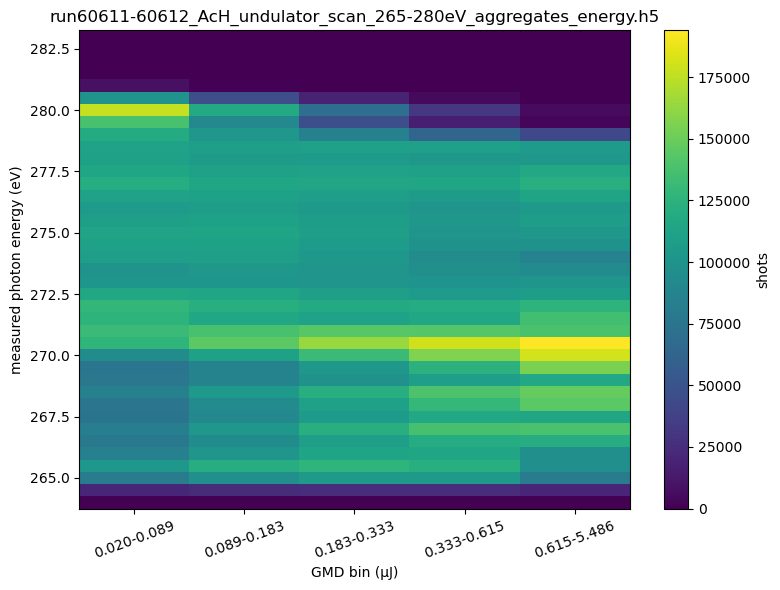

In [5]:
# Shots per cell
fig, ax = plt.subplots(figsize=(8, 6))
mesh = ax.pcolormesh(np.arange(len(gmd_edges)), E_edges, n, cmap="viridis")
fig.colorbar(mesh, ax=ax, label="shots")
ax.set_xticks(np.arange(len(gmd_edges) - 1) + 0.5,
              [f"{a:.3f}-{b:.3f}" for a, b in zip(gmd_edges[:-1], gmd_edges[1:])], rotation=20)
ax.set(xlabel="GMD bin (µJ)", ylabel="measured photon energy (eV)", title=agg_path.name)
ax.grid(False)
fig.tight_layout()
plt.show()

## Dead time and normalisation monitor

**Dead time.** After a recorded hit the electron detector records no second hit within 1.5 ns and only some up to
~6 ns, which costs most on the fast photolines at high pulse energy (`yield_per_uj_vs_gmd.ipynb`, section 4). `analysis/scripts/compute_ready_counts.py`
goes back to the combined file and writes `<aggregates>_ready.h5`: per TDC tick, the shots that were ready (no hit in
the preceding τ) and the hits among them give −ln(1 − hits / ready), the mean number of electrons without losses,
counted in GMD sub-bins and summed into the aggregates' bins (`D_live`, for several τ):

```
python analysis/scripts/compute_ready_counts.py <aggregates>.h5 --workers 16
```

With a ready file, `Dm` (the means used for the spectra, XAS maps and yields below) is `D_live` at `TAU_NS`;
otherwise `Dm = D`. Second moments (`DtD`, `DtC`, `DtG`) stay as recorded, so covariances keep using `D`. The check
plot compares window totals with −ln P(0), the zero-hit estimate that dead time does not change: choose τ where the
corrected totals stop changing. −ln P(0) itself reads a few % low where the pulse energy varies inside a cell, so
the corrected curves settle at or slightly above 1.

**Monitor.** Yields are divided by a per-cell monitor `M` (`MONITOR`):
- `'gmd'`: mean GMD of the cell (µJ);
- `'vls'`: mean VLS sum over the aggregates' crop (`A` summed over pixels: pedestal and common mode subtracted), in
  10⁴ ADU;
- `'ar'`: the Ar 2p (L2,3) photoline of the residual argon in the cell's own electron spectrum (`Dm`): hits per shot
  in the binding-energy window `AR_BE` (KE = hν − BE at the cell's photon energy) minus a linear background from
  `AR_SIDE` eV on either side. One-photon and separate from the molecular lines; its counting noise adds to the
  yields'.

`M2` = ⟨M²⟩ for the a₁/a₂ fit: `GtG`; the sum of `AtA`; for the Ar line the weighted sum of `DtD` minus its
Poisson (self-pair) term.

In [6]:
# ---- Dead time and monitor: parameters ----------------------------------------------------
READY_H5 = 'auto'          # 'auto': <aggregates>_ready.h5 next to AGG_H5 if it exists; a file name or path; None = off
TAU_NS = 6.0               # dead time (ns) of the stored D_live to use; run 60611 reaches the plateau at 6 ns
MONITOR = 'vls'            # 'gmd' | 'vls' | 'ar': per-cell normaliser of the yields
AR_BE = (246.8, 251.8)     # eV, binding-energy window of the Ar 2p line (2p3/2 248.6, 2p1/2 250.8 eV)
AR_SIDE = 2.0              # eV of background on each side of AR_BE (linear); 0 = no background subtraction

run60611-60612_AcH_undulator_scan_265-280eV_aggregates_energy_ready.h5: Dm = D_live at tau = 6.0 ns (stored: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0] ns, 4 GMD sub-bins)


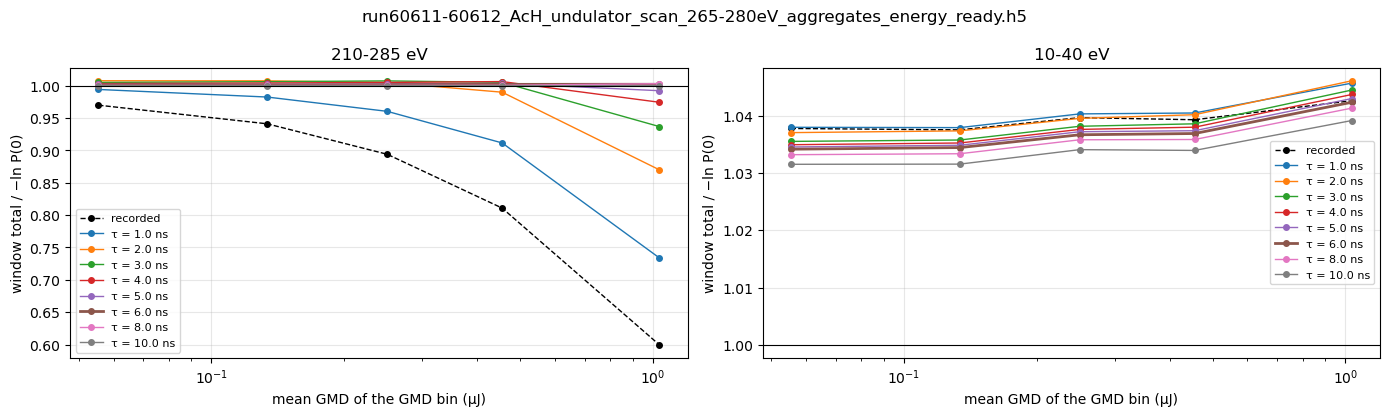

In [7]:
# Dead-time-corrected means Dm from the *_ready.h5 file (D_live at TAU_NS), or the recorded D
from compute_ready_counts import load_ready_counts

ready_path = None
if READY_H5 == 'auto':
    cand = agg_path.with_name(agg_path.stem + '_ready.h5')
    ready_path = cand if cand.exists() else None
elif READY_H5 is not None:
    ready_path = Path(READY_H5) if Path(READY_H5).is_absolute() else config.COMBINED_DIR / READY_H5
Dm = D
if ready_path is None:
    print('no dead-time correction: Dm = D (no *_ready.h5 next to the aggregates, or READY_H5 = None)')
else:
    rd = load_ready_counts(ready_path)
    assert rd['attrs']['check_n_equal'] and np.array_equal(rd['n_per_bin'], n), 'ready file does not match AGG_H5'
    taus = rd['taus_ns']
    k_tau = int(np.argmin(np.abs(taus - TAU_NS)))
    Dm = rd['D_live'][k_tau]
    print(f'{ready_path.name}: Dm = D_live at tau = {taus[k_tau]} ns (stored: {taus.tolist()} ns, '
          f'{rd["attrs"]["gmd_sub"]} GMD sub-bins)')

    # check: window totals / -ln P(0) per GMD bin (shot-weighted over photon energy)
    kc_w = calibration.ke_of_tof(0.5 * (tof_e_edges[1:] + tof_e_edges[:-1]))
    wt = np.where(n > 0, n, 0).astype(float)
    g_x = np.nansum(G * wt, 0) / wt.sum(0)
    wins = rd['p0_windows_ke']
    fig, axs = plt.subplots(1, len(wins), figsize=(7 * len(wins), 4.2), squeeze=False)
    for iw, (ax, (lo, hi)) in enumerate(zip(axs[0], wins)):
        wb = (kc_w >= lo) & (kc_w < hi)
        mu0 = rd['mu0'][..., iw]
        for k in range(-1, len(taus)):
            x = (D if k < 0 else rd['D_live'][k])[..., wb].sum(-1) / mu0
            ok_ = np.isfinite(x) & (wt > 0)
            r = np.where(ok_, x * wt, 0).sum(0) / np.where(ok_, wt, 0).sum(0)
            ax.plot(g_x, r, 'ko--' if k < 0 else 'o-', ms=4, lw=2 if k == k_tau else 1,
                    label='recorded' if k < 0 else f'τ = {taus[k]} ns')
        ax.axhline(1, color='k', lw=0.8)
        ax.set(xscale='log', xlabel='mean GMD of the GMD bin (µJ)', ylabel='window total / −ln P(0)',
               title=f'{lo:.0f}-{hi:.0f} eV')
        ax.legend(fontsize=8)
    fig.suptitle(ready_path.name)
    fig.tight_layout()
    plt.show()

## Calibrated axes: electron energy and ion m/q

`analysis/scripts/calibration.py` (argon run 60538): $E_\mathrm{kin} = (a/(t-t_0))^2 + E_0$ for the electrons,
$m/q = ((t-t_0)/k)^2$ for the ions. Each TOF bin becomes the interval between the images of its edges; dividing by
its width (the Jacobian integrated over the bin) turns hits per bin into hits per eV (per u/e). Second moments and
covariances are divided by the widths of both axes, and covariances formed from the converted arrays are the converted
covariances. The arrays keep the TOF order: along the electron axis the energy falls.

The aggregates were binned in 5 ns electron TOF bins, which at the fast end are tens of eV wide (printed below); to
resolve the fast electrons in energy, aggregate on TOF edges that are images of energy edges (`TOF_EDGES =
10 * calibration.tof_of_ke(ke_edges)[::-1]`).

In [8]:
ke_edges, mq_edges = calibration.ke_of_tof(tof_e_edges), calibration.mq_of_tof(tof_i_edges)
ke, mq = calibration.ke_of_tof(tof_e), calibration.mq_of_tof(tof_i)       # bin centres (TOF order)
dke, dmq = np.abs(np.diff(ke_edges)), np.diff(mq_edges)                   # eV, u/e per bin
per = calibration.per_unit
D_E, DtD_E, DtG_E = per(D, dke), per(DtD, dke, dke), per(DtG, dke)
C_mq, CtC_mq, CtG_mq = per(C, dmq), per(CtC, dmq, dmq), per(CtG, dmq)
DtC_Emq = per(DtC, dke, dmq)
A, AtA, AtD, AtC, AtG = agg.A, agg.AtA, agg.AtD, agg.AtC, agg.AtG       # None without VLS
AtD_E = None if AtD is None else per(AtD, dke)
AtC_mq = None if AtC is None else per(AtC, dmq)

print("electron bins: " + ", ".join(f"{e:.0f} eV -> {w:.2g} eV wide"
                                    for e, w in zip(ke, dke) if any(abs(e - x) < w / 2 for x in (10, 25, 100, 200, 260))))
print("ion bins: " + ", ".join(f"m/q {q:.1f} -> {w:.2g} wide" for q, w in zip(mq, dmq)
                              if any(abs(q - x) < w / 2 for x in (1, 15, 28, 46))))

electron bins: 260 eV -> 1.4 eV wide, 201 eV -> 1.4 eV wide, 102 eV -> 4.9 eV wide, 25 eV -> 1.2 eV wide, 10 eV -> 0.48 eV wide
ion bins: m/q 1.0 -> 0.042 wide, m/q 15.0 -> 0.16 wide, m/q 27.9 -> 0.22 wide, m/q 46.0 -> 0.28 wide


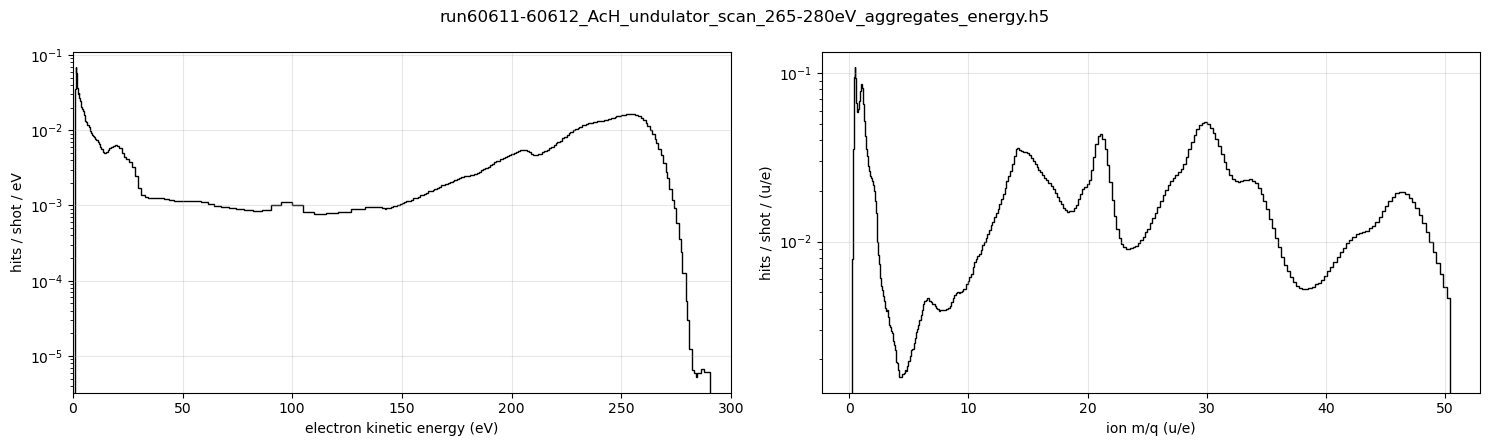

In [9]:
# All cells together (weighted by shots): electron and ion spectra on the calibrated axes
w = n[..., None] / n.sum()
D_all = np.nansum(np.nan_to_num(D_E) * w, axis=(0, 1))
C_all = np.nansum(np.nan_to_num(C_mq) * w, axis=(0, 1))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].stairs(D_all[::-1], ke_edges[::-1], color="k")
axs[0].set(xlabel="electron kinetic energy (eV)", ylabel="hits / shot / eV", yscale="log", xlim=(0, 300))
axs[1].stairs(C_all, mq_edges, color="k")
axs[1].set(xlabel="ion m/q (u/e)", ylabel="hits / shot / (u/e)", yscale="log")
fig.suptitle(agg_path.name)
fig.tight_layout()
plt.show()

MONITOR = 'vls' (10⁴ ADU VLS); Ar 2p window on 39 of 39 photon-energy bins; monitors available: ['gmd', 'vls', 'ar']


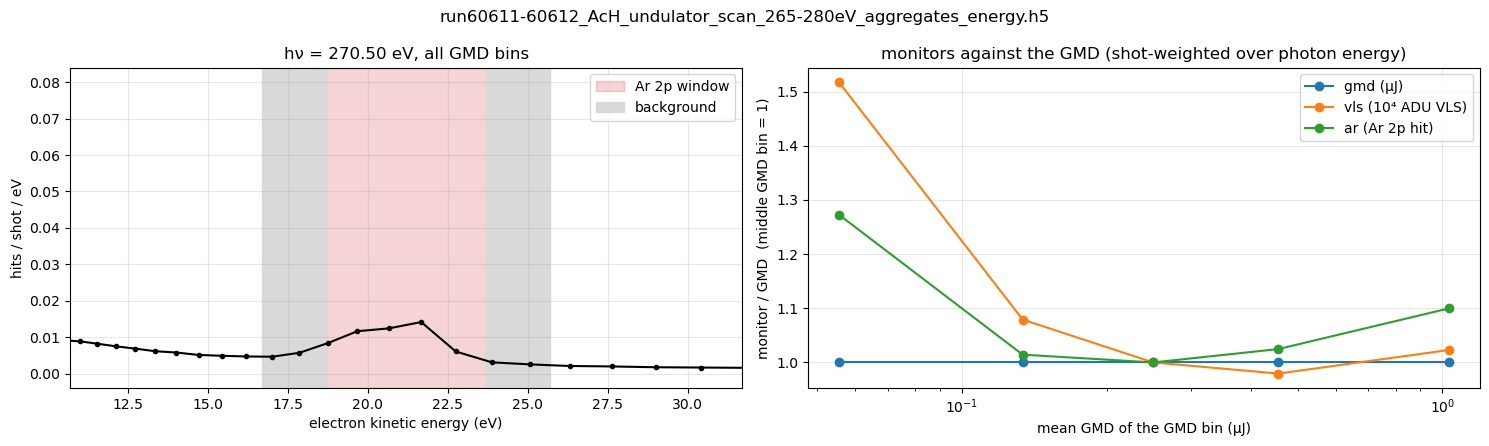

In [10]:
# Per-cell monitors: mean GMD, mean VLS sum over the crop (A), Ar 2p line in Dm; M, M2 = the one chosen in MONITOR
Dm_E = per(Dm, dke)
kc = calibration.ke_of_tof(0.5 * (tof_e_edges[1:] + tof_e_edges[:-1]))      # electron bin centres (TOF order), eV
has_n = n > 0
mon = {'gmd': (G, GtG, 'µJ')}
if A is not None:
    mon['vls'] = (np.where(has_n, np.nansum(A, -1), np.nan) / 1e4,
                  np.where(has_n, np.nansum(AtA, (-1, -2)), np.nan) / 1e8, '10⁴ ADU VLS')

# Ar 2p line: weights per photon-energy row, +1 on the line bins, minus a linear background from the side bands
W_ar = np.full((len(E), len(kc)), np.nan)
for e, hv in enumerate(E):
    lo, hi = hv - AR_BE[1], hv - AR_BE[0]                                    # kinetic-energy window of the line
    line = (kc >= lo) & (kc < hi)
    left, right = (kc >= lo - AR_SIDE) & (kc < lo), (kc >= hi) & (kc < hi + AR_SIDE)
    if not line.any() or (AR_SIDE > 0 and not (left.any() and right.any())):
        continue
    W_ar[e] = 0.0
    W_ar[e, line] = 1.0
    if AR_SIDE > 0:
        W_ar[e, left] = -0.5 * dke[line].sum() / dke[left].sum()
        W_ar[e, right] = -0.5 * dke[line].sum() / dke[right].sum()
ar = np.einsum('eb,egb->eg', W_ar, np.nan_to_num(Dm))
ar2 = (np.einsum('ei,egij,ej->eg', W_ar, np.nan_to_num(DtD), W_ar)
       - np.einsum('eb,egb->eg', W_ar ** 2, np.nan_to_num(D)))               # <M²> without the Poisson self term
mon['ar'] = (np.where(has_n, ar, np.nan), np.where(has_n, ar2, np.nan), 'Ar 2p hit')
M, M2, M_unit = mon[MONITOR]
print(f'MONITOR = {MONITOR!r} ({M_unit}); Ar 2p window on {np.isfinite(W_ar).all(1).sum()} of {len(E)} '
      f'photon-energy bins; monitors available: {list(mon)}')

e_pk = int(np.argmax(n.sum(1)))                                             # photon-energy bin with most shots
o = np.argsort(kc)
spec = np.nansum(Dm_E[e_pk] * n[e_pk, :, None], 0) / n[e_pk].sum()          # hits / shot / eV, all GMD bins
lo, hi = E[e_pk] - AR_BE[1], E[e_pk] - AR_BE[0]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].plot(kc[o], spec[o], 'k.-')
axs[0].axvspan(lo, hi, color='C3', alpha=0.2, label='Ar 2p window')
if AR_SIDE > 0:
    axs[0].axvspan(lo - AR_SIDE, lo, color='0.85', label='background')
    axs[0].axvspan(hi, hi + AR_SIDE, color='0.85')
axs[0].set(xlim=(lo - 8, hi + 8), xlabel='electron kinetic energy (eV)', ylabel='hits / shot / eV',
           title=f'hν = {E[e_pk]:.2f} eV, all GMD bins')
axs[0].legend()
wt = np.where(has_n, n, 0).astype(float)
g_x = np.nansum(G * wt, 0) / wt.sum(0)
for k, (mm, _, unit) in mon.items():
    x = mm / G
    ok_ = np.isfinite(x) & (wt > 0)
    r = np.where(ok_, x * wt, 0).sum(0) / np.where(ok_, wt, 0).sum(0)
    axs[1].plot(g_x, r / r[len(r) // 2], 'o-', label=f'{k} ({unit})')
axs[1].set(xscale='log', xlabel='mean GMD of the GMD bin (µJ)', ylabel='monitor / GMD  (middle GMD bin = 1)',
           title='monitors against the GMD (shot-weighted over photon energy)')
axs[1].legend()
fig.suptitle(agg_path.name)
fig.tight_layout()
plt.show()

## XAS maps: photon energy × electron kinetic energy, one per GMD bin

Each panel is one GMD bin. A row is one measured-photon-energy bin and the colour is the mean electron spectrum of
that cell on the calibrated kinetic-energy axis (`Dm_E`: hits / shot / eV, Jacobian included, dead-time corrected
when there is a ready file). With `XAS_NORM = "monitor"` every cell is divided by its own monitor `M` (`MONITOR`:
GMD, VLS sum or Ar 2p line), so the panels compare directly: a response linear in pulse energy looks the same in
every panel. Cells with fewer than `XAS_MIN_SHOTS` shots are blank. Photolines run
along the diagonal (KE = hν − E_B), Auger lines are vertical (fixed KE).

In [11]:
# ---- XAS maps: parameters ------------------------------------------------------------
XAS_KE = (0, 290)            # electron kinetic-energy range shown (eV)
XAS_NORM = "monitor"         # "monitor": hits / M / eV (each cell / its monitor, MONITOR); "shot": hits / shot / eV
XAS_LOG = True               # log colour scale
XAS_SHARED_CLIM = True       # one colour scale for all GMD bins (False: one per panel)
XAS_MIN_SHOTS = 300          # cells with fewer shots are left blank

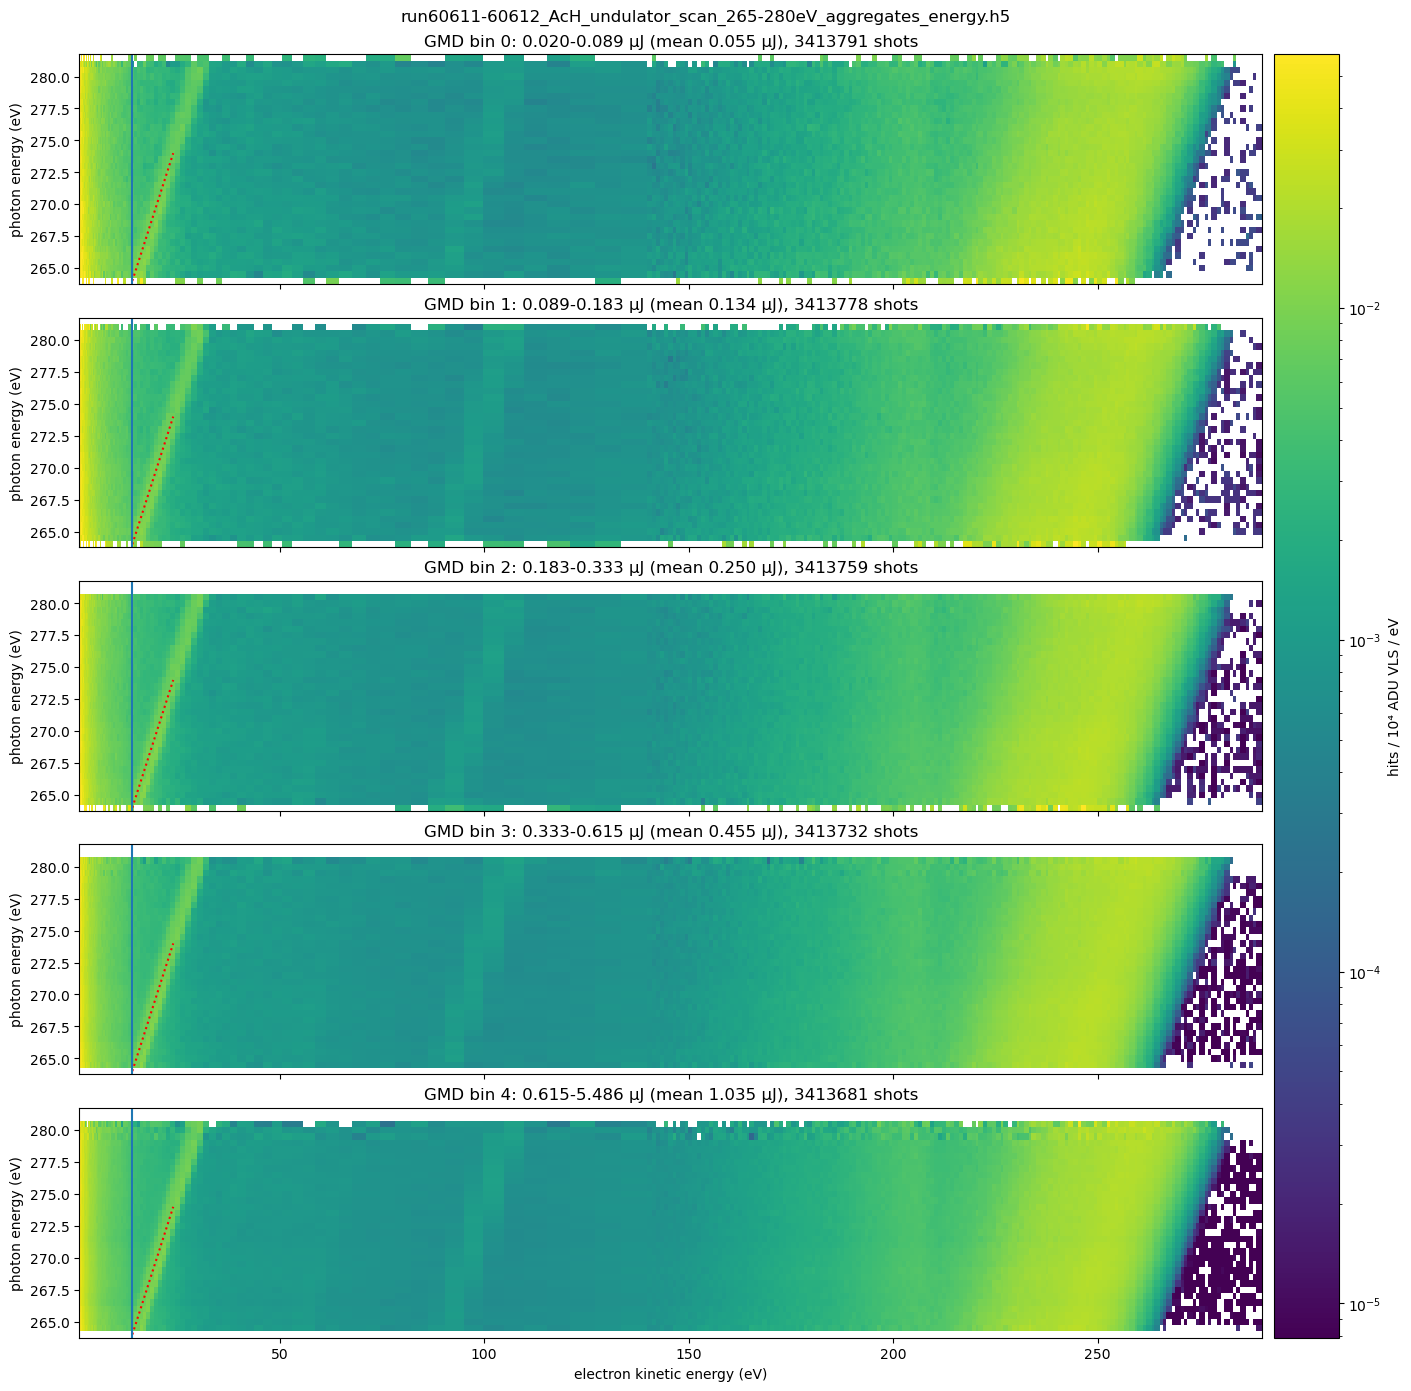

In [12]:
from matplotlib.colors import LogNorm, Normalize

# Per-eV spectra of every (photon energy, GMD) cell on rising kinetic energy (D_E is in TOF order = falling energy)
xas_edges, xas_maps = ke_edges[::-1], Dm_E[..., ::-1]
if XAS_NORM in ("monitor", "gmd"):
    xas_maps = xas_maps / M[..., None]
xas_maps = np.where((n >= XAS_MIN_SHOTS)[..., None], xas_maps, np.nan)
xas_ke = 0.5 * (xas_edges[1:] + xas_edges[:-1])
cols = np.flatnonzero((xas_ke >= XAS_KE[0]) & (xas_ke <= XAS_KE[1]))
xas_maps, xas_edges = xas_maps[..., cols], xas_edges[cols[0]:cols[-1] + 2]
rows = np.flatnonzero(np.isfinite(xas_maps).any(axis=(1, 2)))            # photon-energy bins with data
xas_unit = f"hits / {M_unit} / eV" if XAS_NORM in ("monitor", "gmd") else "hits / shot / eV"


def xas_norm(a):
    v = a[np.isfinite(a) & (a > 0)] if XAS_LOG else a[np.isfinite(a)]
    if not v.size:
        return None
    lo, hi = np.percentile(v, [1, 99.5])
    return LogNorm(lo, hi) if XAS_LOG else Normalize(lo, hi)


n_g = xas_maps.shape[1]
fig, axs = plt.subplots(n_g, 1, figsize=(14, 2.6 * n_g + 0.8), sharex=True, squeeze=False, constrained_layout=True)
axs = axs[:, 0]
shared = xas_norm(xas_maps) if XAS_SHARED_CLIM else None
for j, ax in enumerate(axs):
    m = ax.pcolormesh(xas_edges, E_edges, np.ma.masked_invalid(xas_maps[:, j]), cmap="viridis",
                      norm=shared if XAS_SHARED_CLIM else xas_norm(xas_maps[:, j]))
    if not XAS_SHARED_CLIM:
        fig.colorbar(m, ax=ax, label=xas_unit, pad=0.01)
    g_mean = np.nansum(G[:, j] * n[:, j]) / max(n[:, j].sum(), 1)
    ax.set(ylabel="photon energy (eV)", ylim=(E_edges[rows[0]], E_edges[rows[-1] + 1]),
           title=f"GMD bin {j}: {gmd_edges[j]:.3f}-{gmd_edges[j + 1]:.3f} µJ (mean {g_mean:.3f} µJ), "
                 f"{n[:, j].sum()} shots")
    ax.grid(False)
axs[-1].set_xlabel("electron kinetic energy (eV)")
if XAS_SHARED_CLIM:
    fig.colorbar(m, ax=list(axs), label=xas_unit, pad=0.01)
fig.suptitle(agg_path.name)
xtest = np.linspace(0,10,31)
for ax in axs:
    ax.plot(xtest+14, xtest+264, 'r:')
    ax.axvline(14)
    ax.grid(True, which='minor')
plt.show()

(0.0, 400.0)

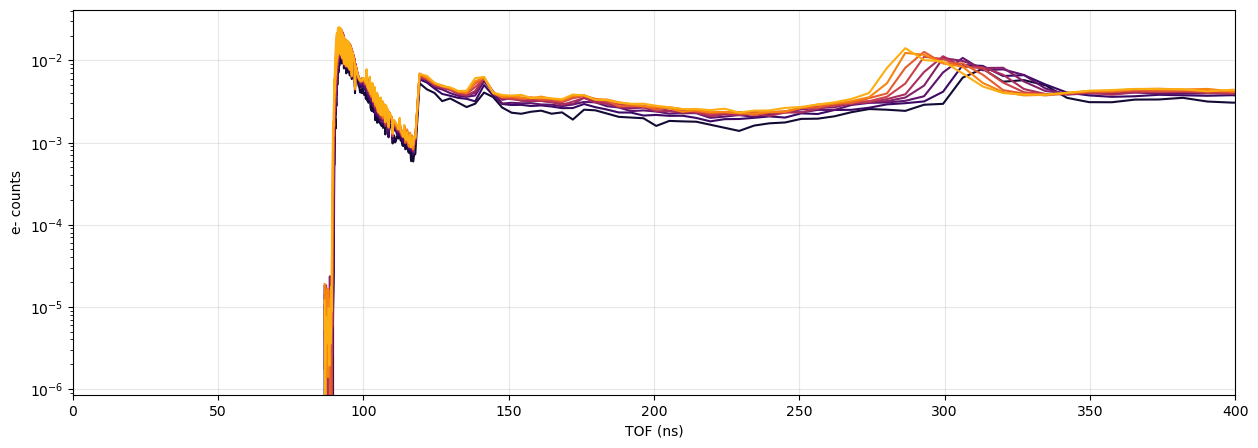

In [13]:
fig, ax = plt.subplots(figsize=(15,5))
ax.set_prop_cycle(plt.cycler('color', sns.color_palette('inferno', D[:10].shape[0])))
ax.semilogy(tof_e, D.mean(1)[1:10].T)
ax.set_xlabel('TOF (ns)')
ax.set_ylabel('e- counts')
ax.set_xlim(0, 400)

In [14]:
D.shape

(39, 5, 252)

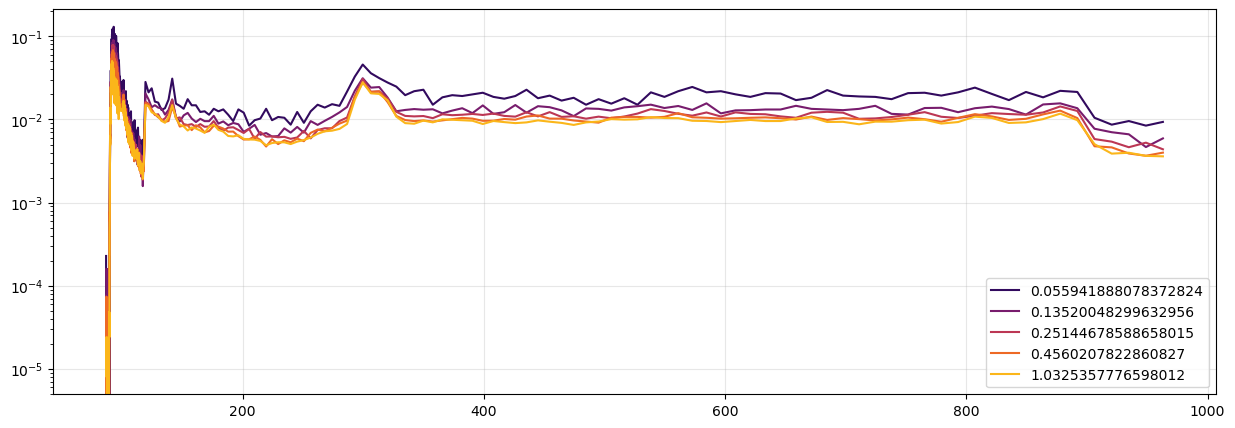

In [15]:
idx = 5
fig, ax = plt.subplots(figsize=(15,5))
ax.set_prop_cycle(plt.cycler('color', sns.color_palette('inferno', D.shape[1])))
ax.semilogy(tof_e, D[idx].T/G[idx])
# ax.plot(tof_e, D[idx].T)
ax.legend(G[idx])
# ax.set_xlim(50,200)

/tmp/ipykernel_4121681/3357664626.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


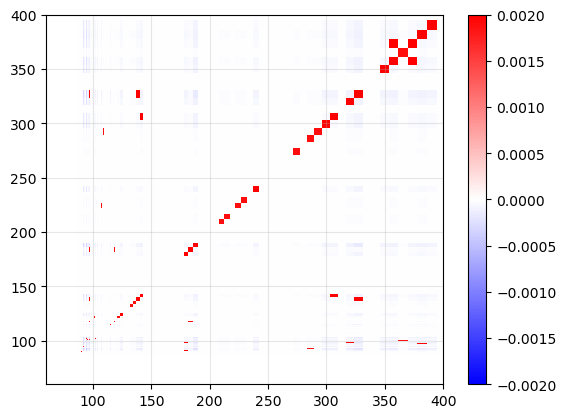

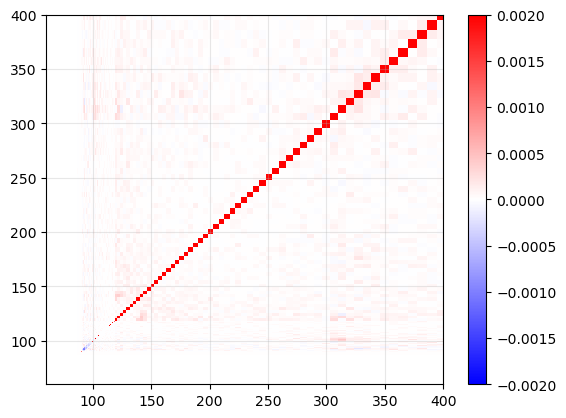

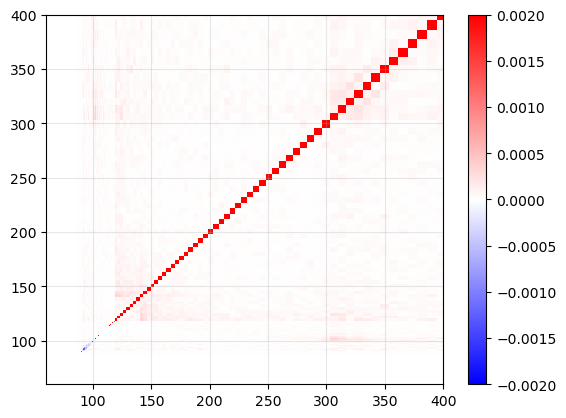

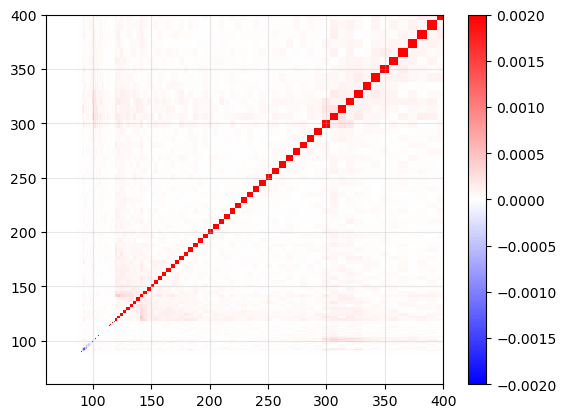

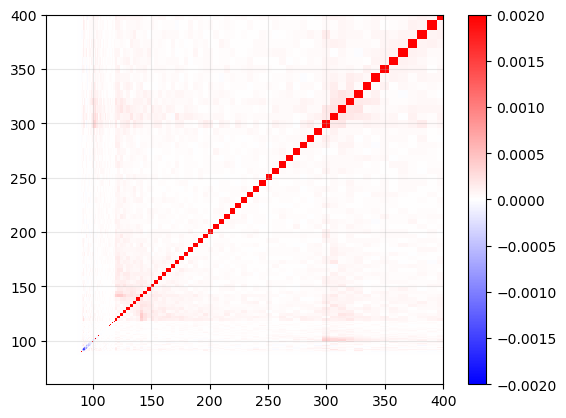

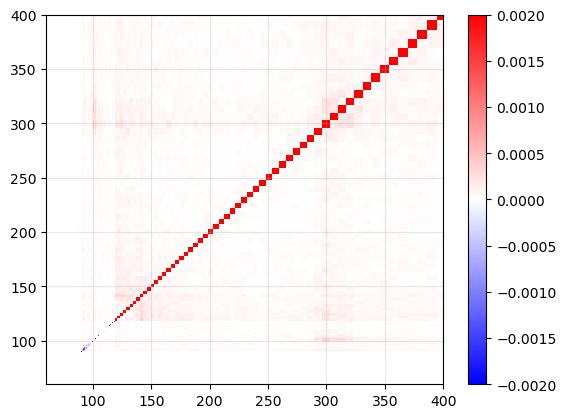

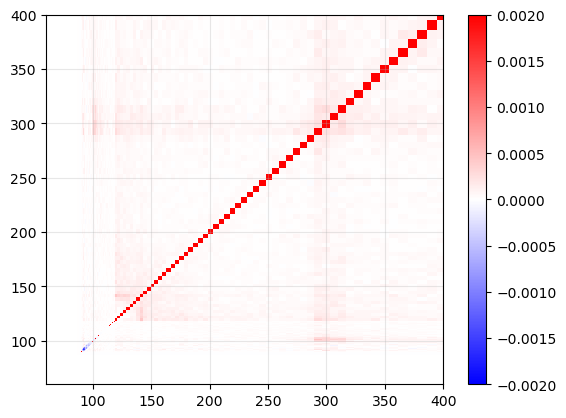

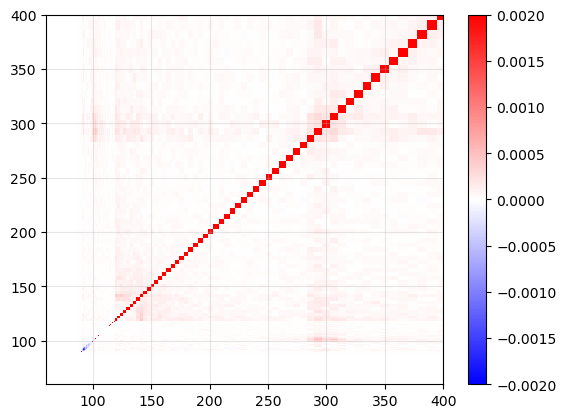

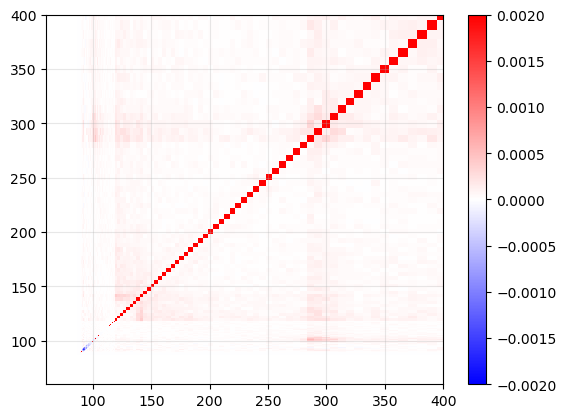

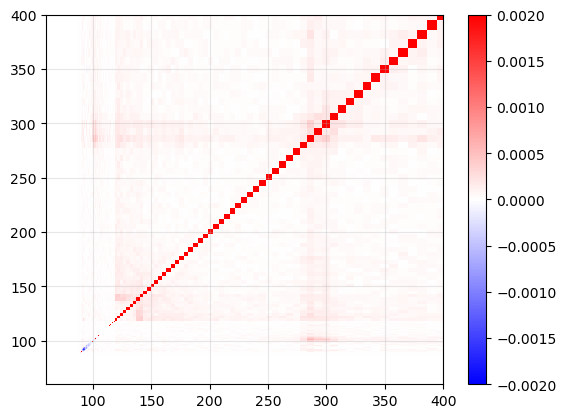

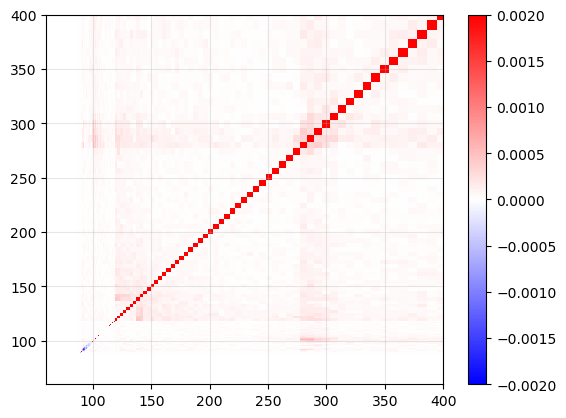

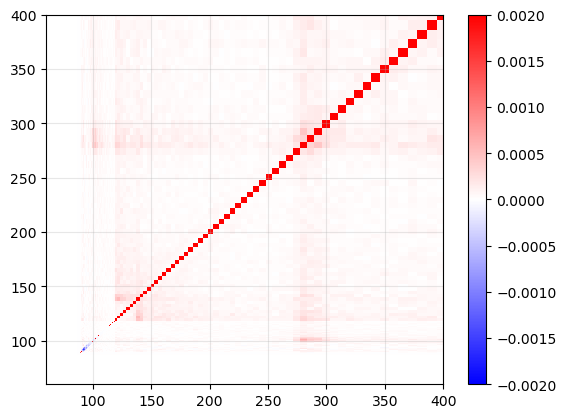

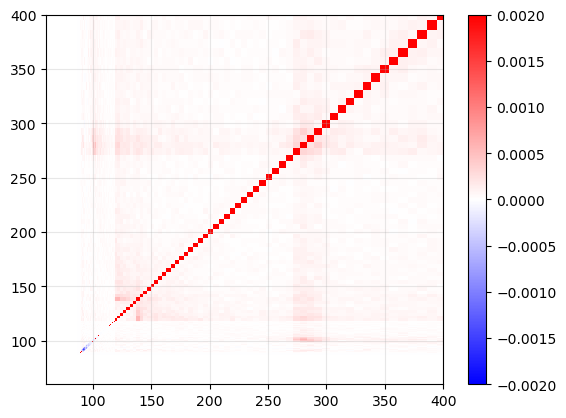

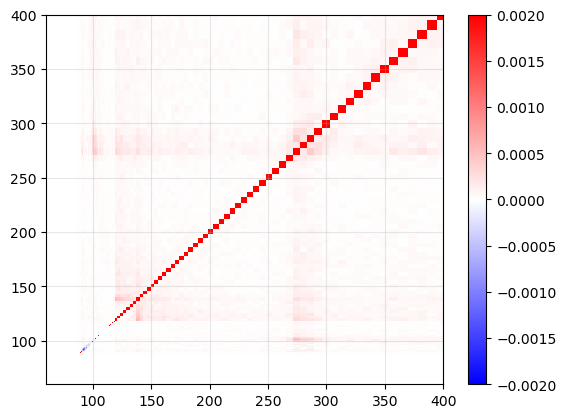

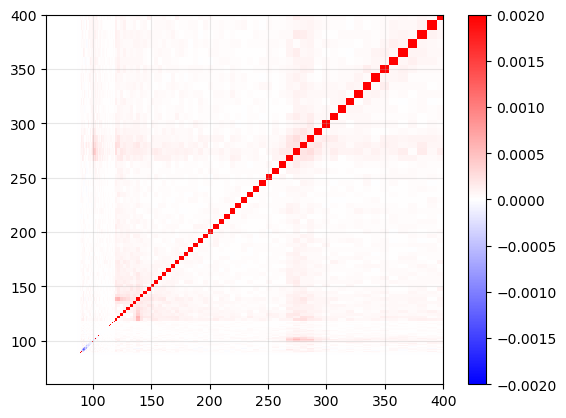

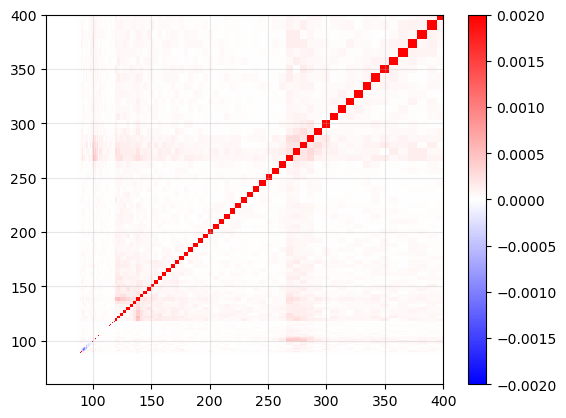

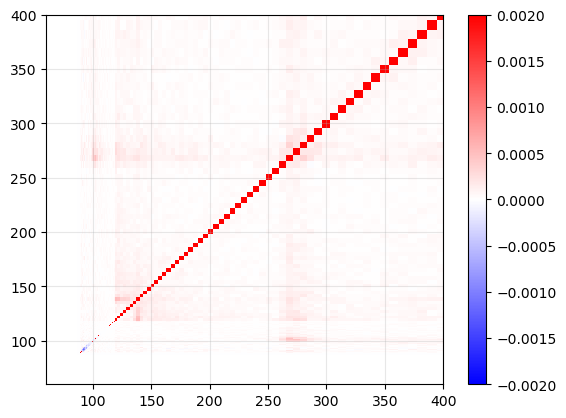

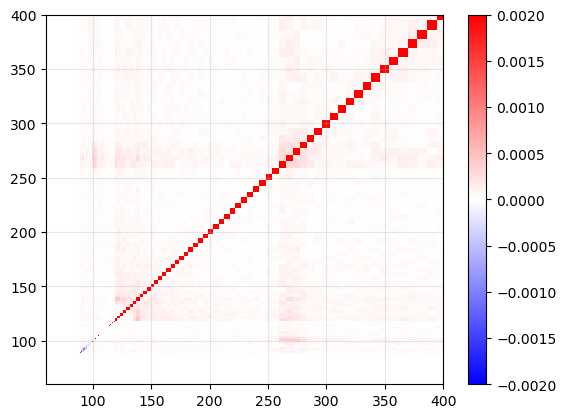

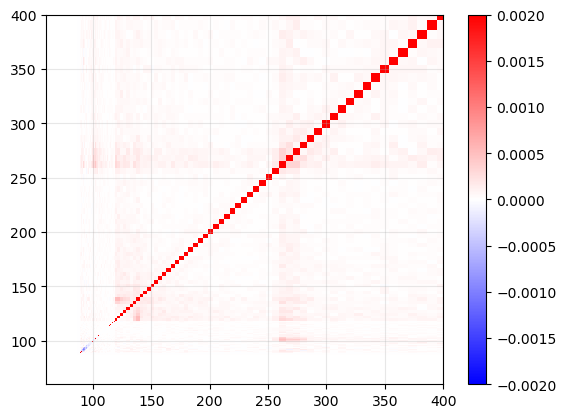

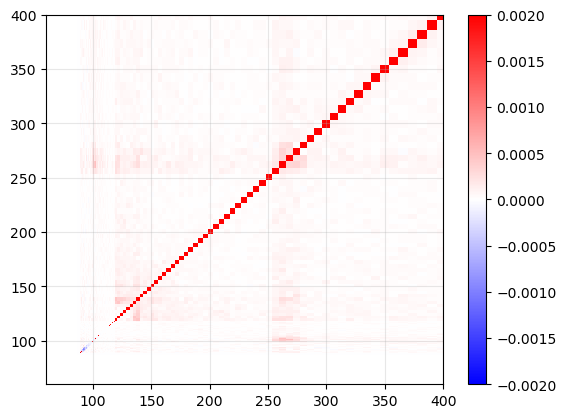

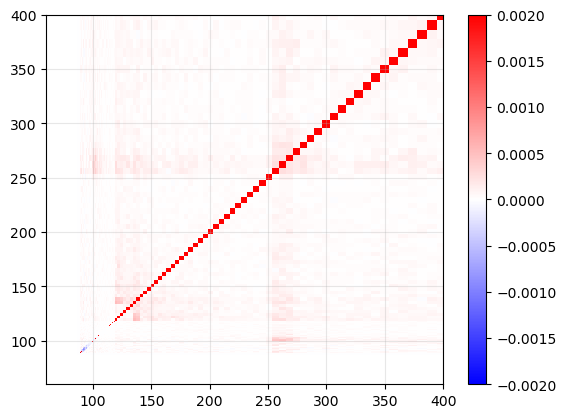

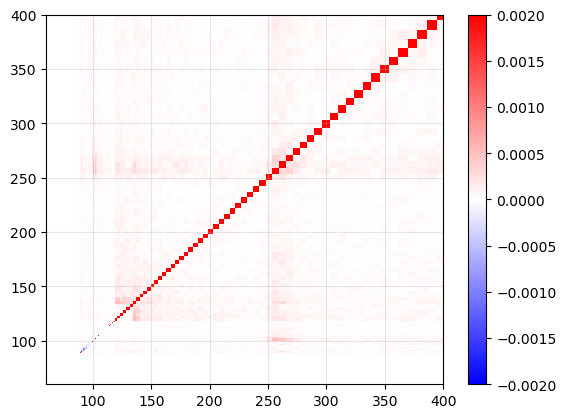

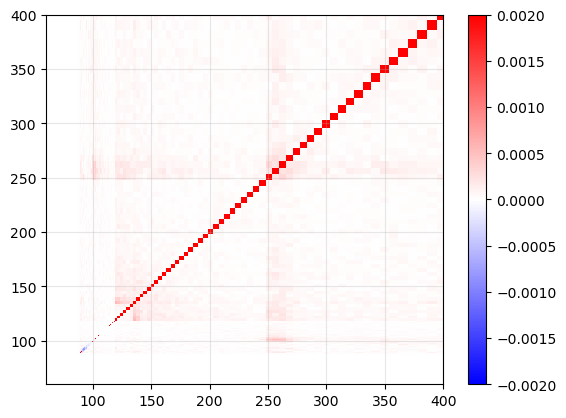

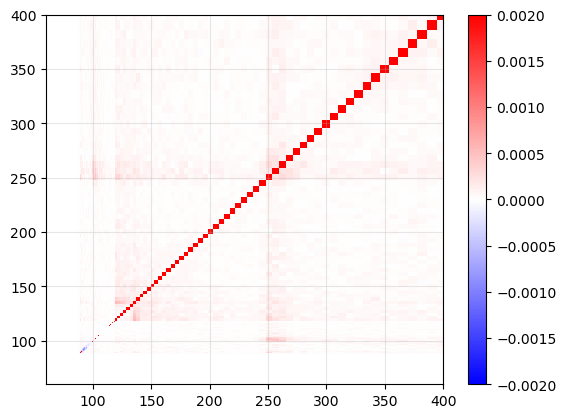

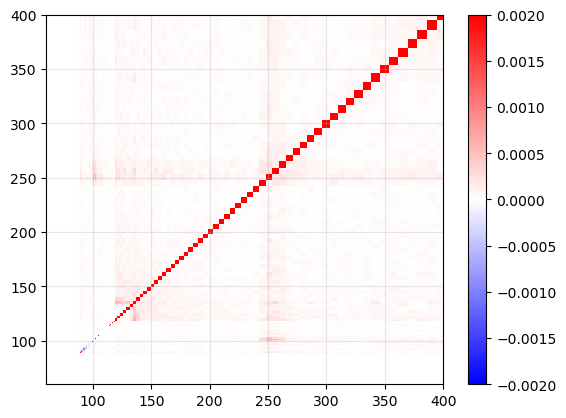

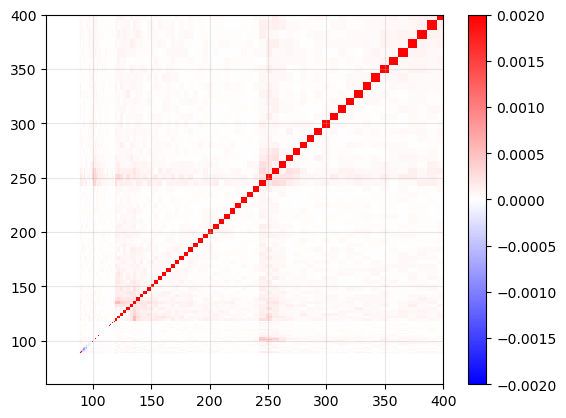

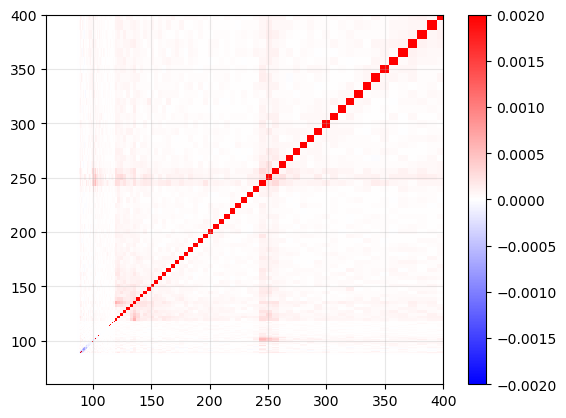

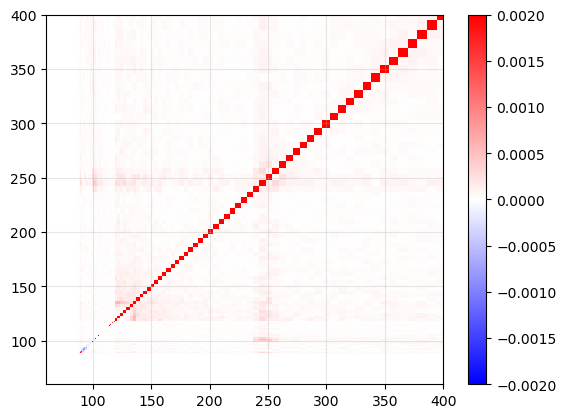

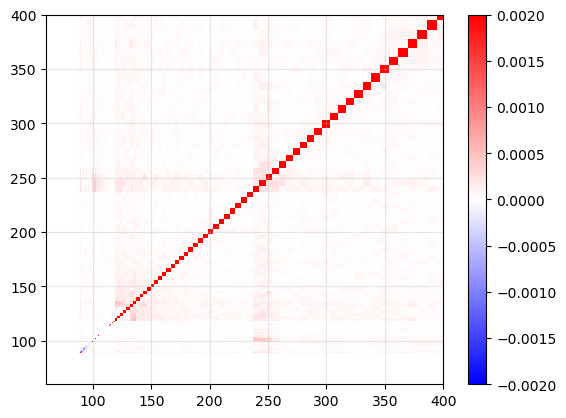

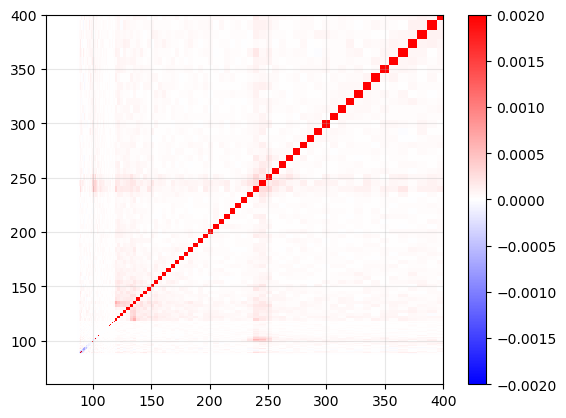

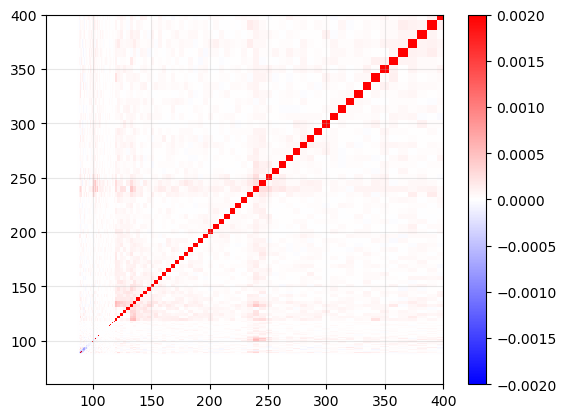

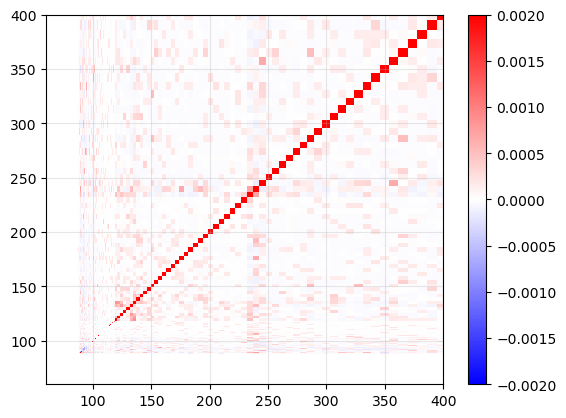

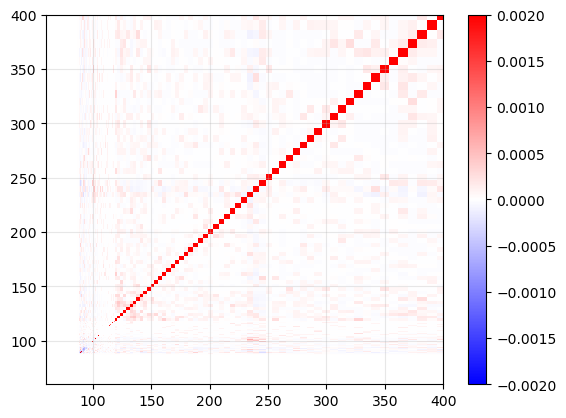

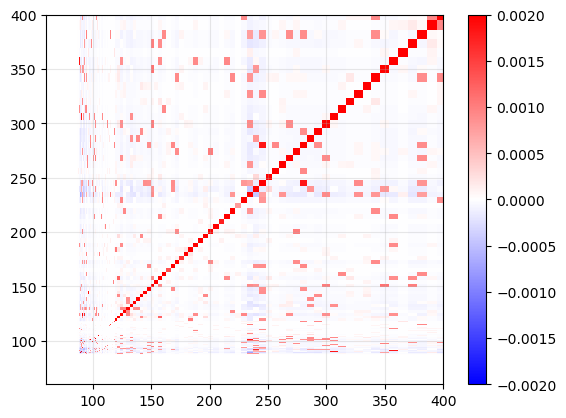

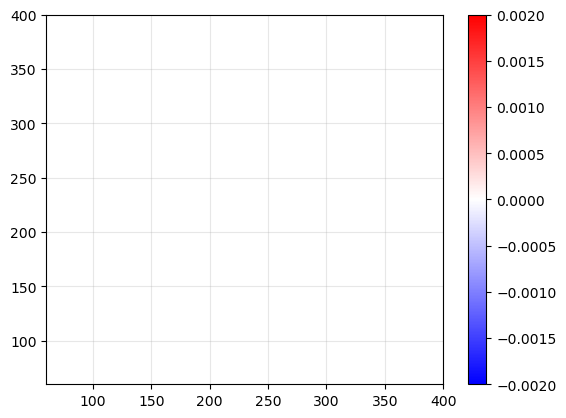

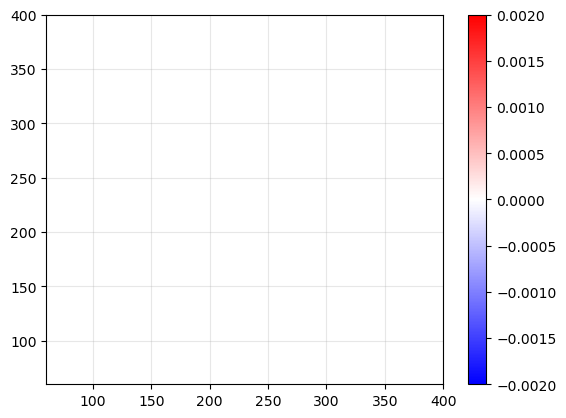

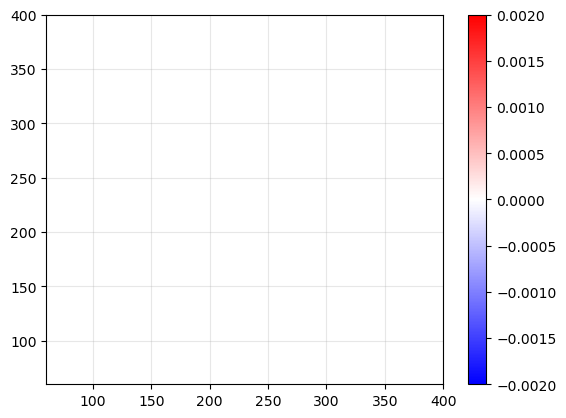

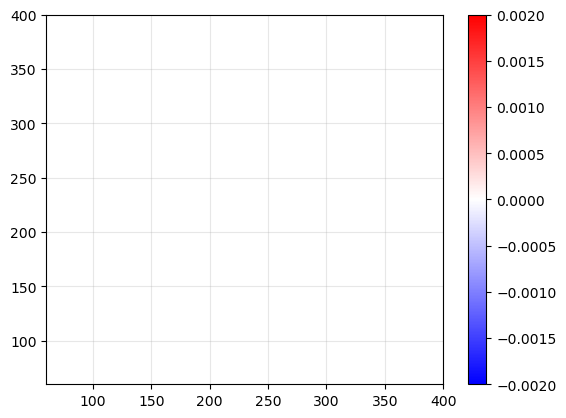

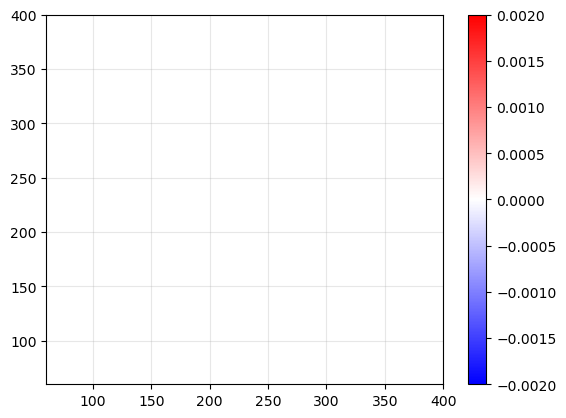

In [16]:
for d, dtd in zip(D[:,3:].mean(1), DtD[:,3:].mean(1)):
    covdd = dtd - np.outer(d,d)
    
    fig, ax = plt.subplots()
    mesh = ax.pcolormesh(tof_e, tof_e, covdd, cmap = 'bwr', clim=(-2e-3, 2e-3))
    plt.colorbar(mesh, ax=ax)
    ax.set_xlim(60, 400)
    ax.set_ylim(60, 400)

## Two-photon resonance: core → valence-hole excitation within one pulse

**Question.** Does a resonant channel open at high pulse energy in which one photon ionises the valence and a second
photon of the same pulse excites a core (C 1s) electron into the valence hole, the core-excited cation then decaying by
(resonant) Auger emission? Such a channel needs two photons, so its yield grows as G², and it is resonant: it appears at
the cation's core → valence-hole transition energy, roughly the C 1s binding energy minus the valence-hole energy
(≈ 291 − 11 ≈ 280 eV for a HOMO hole; deeper valence holes lie lower), i.e. inside this scan.

**Three views**, all from the aggregates (shots with a measured photon energy; cells with fewer than `MIN_SHOTS` shots
left out):
1. **Partial-yield XAS of fast electrons**: hits per shot in `HIGH_KE` against the measured photon energy, per monitor unit
   (`MONITOR`) for each GMD bin and relative to a one-photon reference window `REF_KE`. In each photon-energy bin a weighted fit
   ⟨N⟩ = a₁⟨M⟩ + a₂⟨M²⟩ over the GMD bins (`M`, `M2`); a two-photon resonance is a photon-energy-localised rise of
   a₂/a₁ and of the high/low-GMD ratio of the reference-normalised yield (GMD bins `HI_GMD_BINS` / `LO_GMD_BINS`
   pooled). The fit uses only photon-energy bins where every GMD bin has enough shots, so that its leverage is the same
   at all photon energies.
2. **Where in kinetic energy**: per-µJ spectra of the high GMD bins and their ratio to the low GMD bins, divided by that
   ratio's median over photon energy, so that only photon-energy-specific changes remain.
3. **Covariance**, partial on GMD within each cell, then averaged over the GMD bins `COV_GMD_BINS` (weighted by shots):
   electron pairs inside `HIGH_KE` (pairs closer than `DEAD_TIME_NS` in TOF left out: the detector dead time makes
   them negative), and the fast-electron count against the ion m/q spectrum.

**Caveat.** Per GMD µJ every detected yield falls across the GMD bins (the fast electrons by 2-3x).
`yield_per_uj_vs_gmd.ipynb` traces this to the noise of the hall GMD reading (lowest bins), dead time on the fast
lines at high pulse energy, and a fall common to all channels that the GMD does not account for. `Dm` (ready file)
removes the dead-time part from the means and `MONITOR` changes the normaliser; the pair covariance inside a window
is still negative from dead time (pairs closer than `DEAD_TIME_NS` are left out). The reference-normalised ratio
removes the part common to all electrons.

In [17]:
# ---- Two-photon resonance: parameters ------------------------------------------
HIGH_KE = (210, 285)        # eV: fast electrons (valence photolines, resonant Auger); above the Ar L2,3-M2,3M2,3 Auger
REF_KE = (10, 40)           # eV: one-photon reference window (incl. the residual Ar 2p line)
MIN_SHOTS = 300             # cells (photon energy x GMD) with fewer shots are left out
HI_GMD_BINS = None          # GMD bins pooled as "high" / "low" for the ratios; None = top two / bottom two
LO_GMD_BINS = None
DEAD_TIME_NS = 1.0          # electron pairs closer than this in TOF are left out of the pair covariance
COV_GMD_BINS = None         # GMD bins averaged for the covariance maps; None = the top two
MAP_KE = (150, 285)         # eV, kinetic-energy range of the maps
MAP_REBIN = 6               # electron bins merged in the kinetic-energy ratio map
COMPARE_E = (280.0, 268.0)  # photon energies (eV) for the e-e maps: near the expected cation C 1s -> HOMO-hole
                            # resonance, and well below it

In [18]:
# Per cell (photon energy x GMD): hits per shot in the windows and the a1 / a2 fit per photon-energy bin
kc = calibration.ke_of_tof(0.5 * (tof_e_edges[1:] + tof_e_edges[:-1]))   # electron bin centres (TOF order)
w_hi = (kc >= HIGH_KE[0]) & (kc < HIGH_KE[1])
w_rf = (kc >= REF_KE[0]) & (kc < REF_KE[1])
ok = n >= MIN_SHOTS
n_g = n.shape[1]


def window_moments(w):
    # recorded mean hits per shot in the window, its standard error, <N G>, and the mean from Dm
    m = D[..., w].sum(-1)
    m2 = DtD[:, :, w][:, :, :, w].sum((-1, -2))
    se = np.sqrt(np.maximum(m2 - m ** 2, 0) / np.maximum(n, 1))
    return m, se, DtG[..., w].sum(-1), Dm[..., w].sum(-1)


N_hi_rec, se_hi, NG_hi, N_hi = window_moments(w_hi)               # N_hi, N_rf: from Dm (dead-time corrected)
N_rf_rec, se_rf, _, N_rf = window_moments(w_rf)
with np.errstate(invalid="ignore", divide="ignore"):
    se_hi, se_rf = se_hi * N_hi / N_hi_rec, se_rf * N_rf / N_rf_rec       # errors scaled to the corrected means
with np.errstate(invalid="ignore", divide="ignore"):
    y_M = np.where(ok, N_hi / M, np.nan)                        # fast electrons per monitor unit
    y_M_se = se_hi / M
    y_rel = np.where(ok, N_hi / N_rf, np.nan)                   # relative to the reference window
    y_rel_se = y_rel * np.sqrt((se_hi / N_hi) ** 2 + (se_rf / N_rf) ** 2)

a1, a2, r21, r21_se = (np.full(len(E), np.nan) for _ in range(4))
for e in range(len(E)):
    k = ok[e]
    if not k.all():                                             # same leverage at every photon energy
        continue
    X = np.c_[M[e, k], M2[e, k]]
    wt = 1 / se_hi[e, k] ** 2
    cv = np.linalg.inv(X.T @ (X * wt[:, None]))
    a1[e], a2[e] = cv @ (X.T @ (wt * N_hi[e, k]))
    r21[e] = a2[e] / a1[e]
    r21_se[e] = abs(r21[e]) * np.sqrt(cv[1, 1] / a2[e] ** 2 + cv[0, 0] / a1[e] ** 2 - 2 * cv[0, 1] / (a1[e] * a2[e]))

gh = list(HI_GMD_BINS) if HI_GMD_BINS is not None else [n_g - 2, n_g - 1]
gl_ = list(LO_GMD_BINS) if LO_GMD_BINS is not None else [0, 1]


def pooled(x, gs):
    # shot-weighted mean over GMD bins gs per photon-energy bin (NaN unless all of them have enough shots)
    wts = n[:, gs].astype(float)
    shp = wts.shape + (1,) * (x.ndim - 2)
    out = (np.nan_to_num(x[:, gs]) * wts.reshape(shp)).sum(1) / wts.sum(1).reshape((-1,) + shp[2:])
    return np.where(ok[:, gs].all(1).reshape((-1,) + shp[2:]), out, np.nan)


def pooled_rel(gs):
    # reference-normalised fast-electron yield of the pooled GMD bins and its standard error
    nh, nr = pooled(N_hi, gs), pooled(N_rf, gs)
    sh = np.sqrt((n[:, gs] ** 2 * se_hi[:, gs] ** 2).sum(1)) / n[:, gs].sum(1)
    sr = np.sqrt((n[:, gs] ** 2 * se_rf[:, gs] ** 2).sum(1)) / n[:, gs].sum(1)
    r = nh / nr
    return r, r * np.sqrt((sh / nh) ** 2 + (sr / nr) ** 2)


r_hi, r_hi_se = pooled_rel(gh)
r_lo, r_lo_se = pooled_rel(gl_)
ratio_hl = r_hi / r_lo
ratio_hl_se = ratio_hl * np.sqrt((r_hi_se / r_hi) ** 2 + (r_lo_se / r_lo) ** 2)
print(f"HIGH_KE {HIGH_KE} eV: {w_hi.sum()} electron bins; REF_KE {REF_KE} eV: {w_rf.sum()} bins; "
      f"{ok.sum()} of {ok.size} cells with >= {MIN_SHOTS} shots")
print(f"{'E (eV)':>7s} {'a2/a1 (1/' + M_unit + ')':>20s} {'hi/lo GMD (ref-norm.)':>22s}")
for e in np.flatnonzero(np.isfinite(r21) | np.isfinite(ratio_hl)):
    print(f"{E[e]:7.2f} {r21[e]:+8.3f} ± {r21_se[e]:.3f}   {ratio_hl[e]:8.3f} ± {ratio_hl_se[e]:.3f}")

HIGH_KE (210, 285) eV: 75 electron bins; REF_KE (10, 40) eV: 28 bins; 171 of 195 cells with >= 300 shots
 E (eV) a2/a1 (1/10⁴ ADU VLS)  hi/lo GMD (ref-norm.)
 264.50   -0.032 ± 0.003      1.050 ± 0.035
 265.00   -0.034 ± 0.001      1.078 ± 0.017
 265.50   -0.036 ± 0.001      1.055 ± 0.014
 266.00   -0.037 ± 0.001      1.057 ± 0.015
 266.50   -0.030 ± 0.001      1.106 ± 0.016
 267.00   -0.028 ± 0.001      1.065 ± 0.014
 267.50   -0.022 ± 0.001      1.086 ± 0.015
 268.00   -0.022 ± 0.001      1.070 ± 0.015
 268.50   -0.022 ± 0.001      1.094 ± 0.014
 269.00   -0.023 ± 0.001      1.027 ± 0.015
 269.50   -0.023 ± 0.001      1.078 ± 0.015
 270.00   -0.023 ± 0.001      1.071 ± 0.013
 270.50   -0.017 ± 0.001      1.051 ± 0.012
 271.00   -0.018 ± 0.001      1.035 ± 0.013
 271.50   -0.018 ± 0.001      1.077 ± 0.014
 272.00   -0.010 ± 0.001      1.052 ± 0.014
 272.50   -0.007 ± 0.001      1.049 ± 0.014
 273.00   -0.005 ± 0.001      1.042 ± 0.015
 273.50   -0.001 ± 0.001      1.054 ± 0.016
 274.0

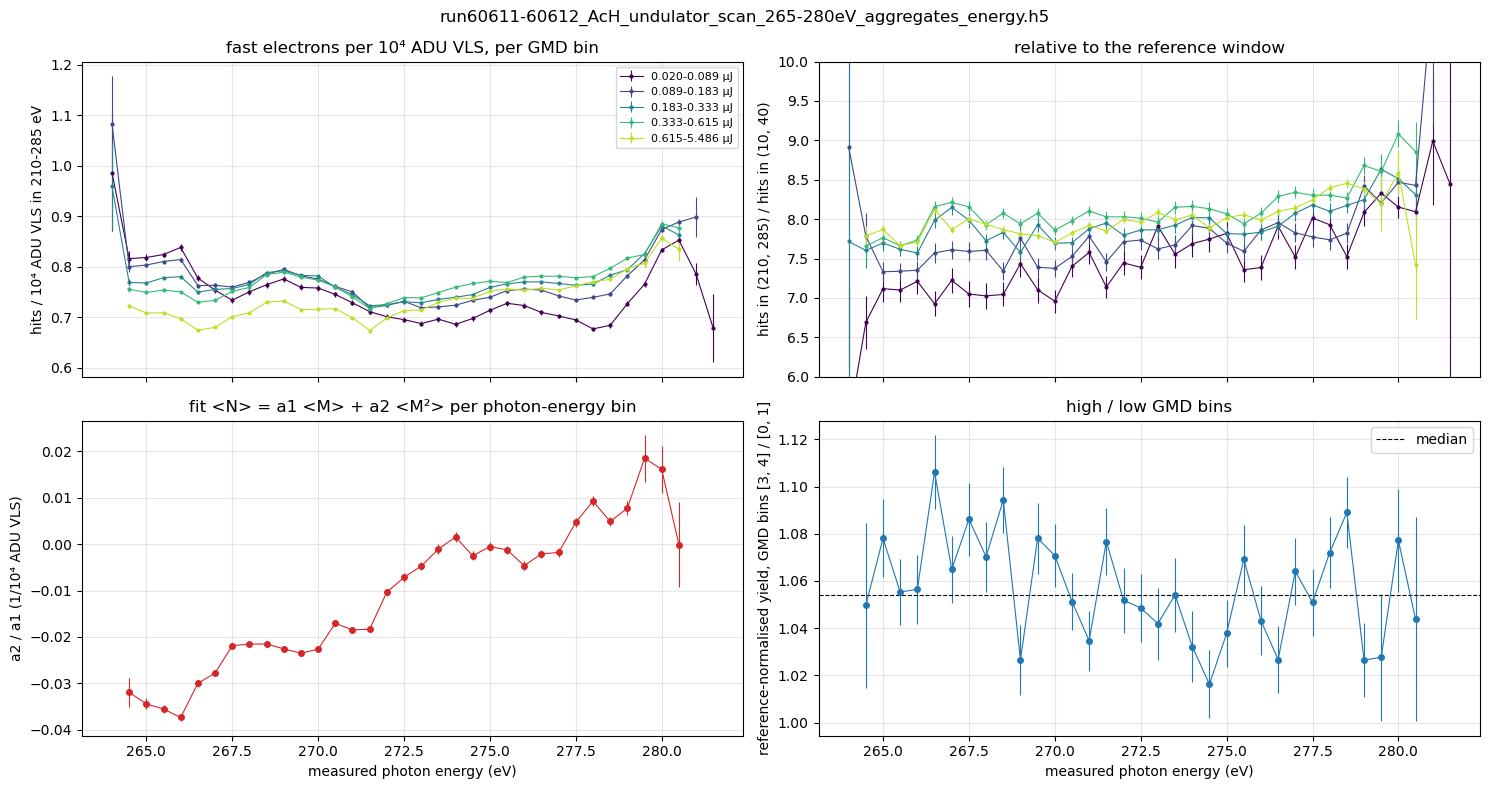

In [19]:
# Partial-yield XAS of the fast electrons
cols_g = plt.cm.viridis(np.linspace(0, 0.9, n_g))
gl = [f"{a:.3f}-{b:.3f} µJ" for a, b in zip(gmd_edges[:-1], gmd_edges[1:])]
fig, axs = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for g in range(n_g):
    axs[0, 0].errorbar(E, y_M[:, g], y_M_se[:, g], fmt=".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
    axs[0, 1].errorbar(E, y_rel[:, g], y_rel_se[:, g], fmt=".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
axs[0, 0].set(ylabel=f"hits / {M_unit} in {HIGH_KE[0]}-{HIGH_KE[1]} eV",
              title=f"fast electrons per {M_unit}, per GMD bin")
axs[0, 1].set(ylabel=f"hits in {HIGH_KE} / hits in {REF_KE}", title="relative to the reference window")
axs[0, 0].legend(fontsize=8)
axs[1, 0].errorbar(E, r21, r21_se, fmt="o-", ms=4, lw=0.8, color="C3")
axs[1, 0].set(ylabel=f"a2 / a1 (1/{M_unit})", title="fit <N> = a1 <M> + a2 <M²> per photon-energy bin")
axs[1, 1].errorbar(E, ratio_hl, ratio_hl_se, fmt="o-", ms=4, lw=0.8, color="C0")
axs[1, 1].axhline(np.nanmedian(ratio_hl), color="k", lw=0.8, ls="--", label="median")
axs[1, 1].set(ylabel=f"reference-normalised yield, GMD bins {gh} / {gl_}", title="high / low GMD bins")
axs[1, 1].legend()
axs[0,1].set_ylim(6, 10)
for ax in axs[1]:
    ax.set_xlabel("measured photon energy (eV)")
fig.suptitle(agg_path.name)
fig.tight_layout()
# axs[1,0].set_ylim(-.3, -.2)
plt.show()

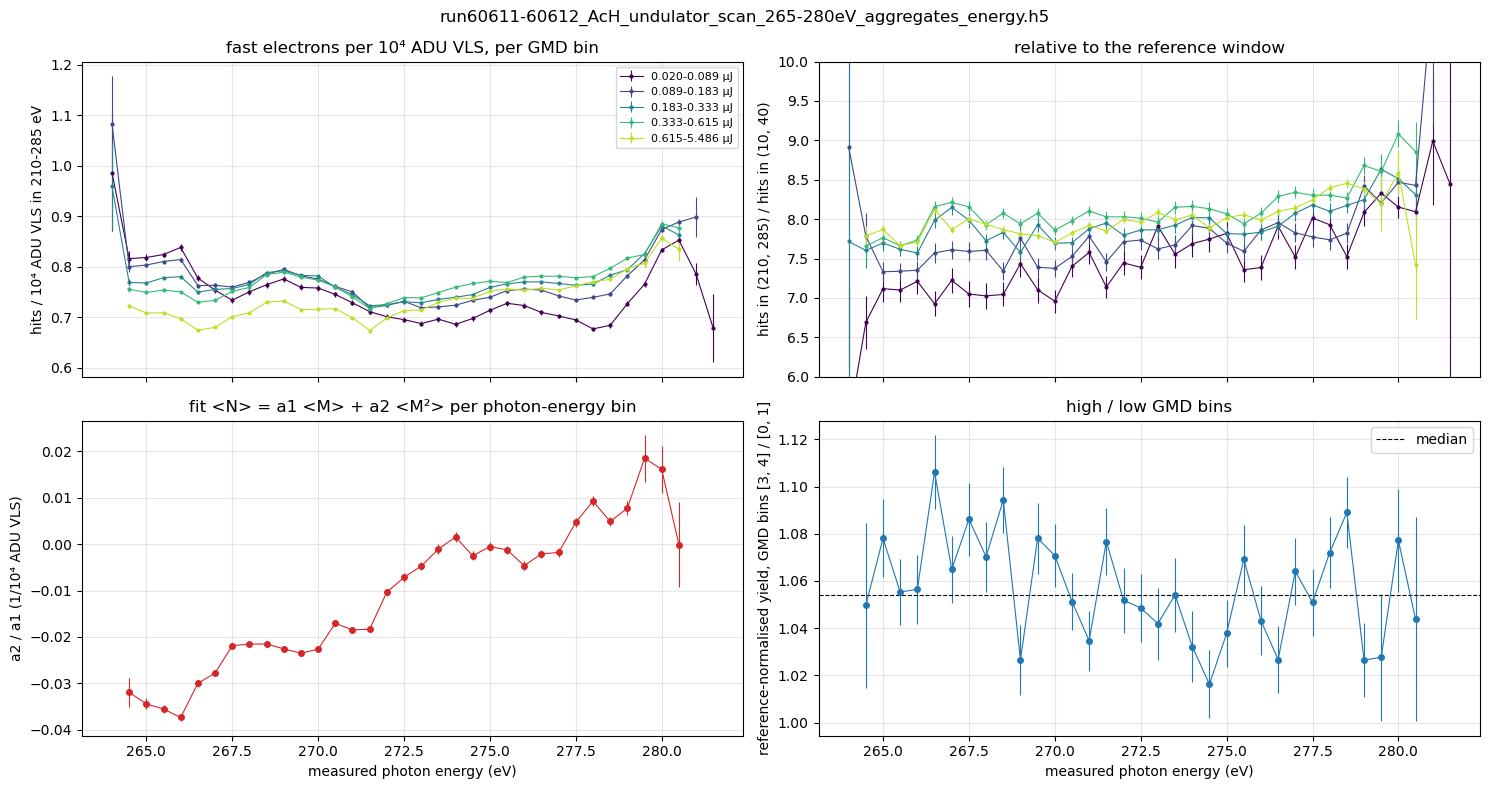

In [20]:
# Partial-yield XAS of the fast electrons
cols_g = plt.cm.viridis(np.linspace(0, 0.9, n_g))
gl = [f"{a:.3f}-{b:.3f} µJ" for a, b in zip(gmd_edges[:-1], gmd_edges[1:])]
fig, axs = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for g in range(n_g):
    axs[0, 0].errorbar(E, y_M[:, g], y_M_se[:, g], fmt=".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
    axs[0, 1].errorbar(E, y_rel[:, g], y_rel_se[:, g], fmt=".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
axs[0, 0].set(ylabel=f"hits / {M_unit} in {HIGH_KE[0]}-{HIGH_KE[1]} eV",
              title=f"fast electrons per {M_unit}, per GMD bin")
axs[0, 1].set(ylabel=f"hits in {HIGH_KE} / hits in {REF_KE}", title="relative to the reference window")
axs[0, 0].legend(fontsize=8)
axs[1, 0].errorbar(E, r21, r21_se, fmt="o-", ms=4, lw=0.8, color="C3")
axs[1, 0].set(ylabel=f"a2 / a1 (1/{M_unit})", title="fit <N> = a1 <M> + a2 <M²> per photon-energy bin")
axs[1, 1].errorbar(E, ratio_hl, ratio_hl_se, fmt="o-", ms=4, lw=0.8, color="C0")
axs[1, 1].axhline(np.nanmedian(ratio_hl), color="k", lw=0.8, ls="--", label="median")
axs[1, 1].set(ylabel=f"reference-normalised yield, GMD bins {gh} / {gl_}", title="high / low GMD bins")
axs[1, 1].legend()
axs[0,1].set_ylim(6, 10)
for ax in axs[1]:
    ax.set_xlabel("measured photon energy (eV)")
fig.suptitle(agg_path.name)
fig.tight_layout()
# axs[1,0].set_ylim(-.3, -.2)
plt.show()

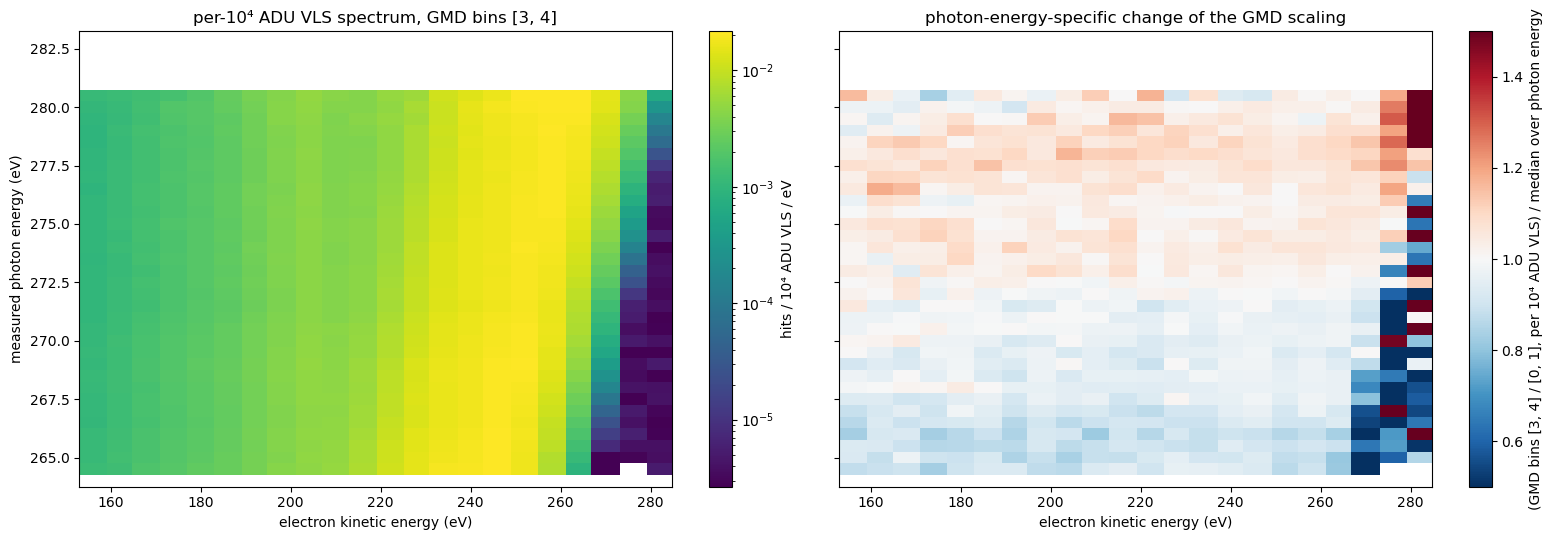

In [21]:
from matplotlib.colors import LogNorm

# Kinetic-energy resolved: per-µJ spectra at the highest GMD bin and the high/low ratio relative to its median over
# photon energy (1 = same GMD scaling as at the other photon energies)
sel = np.flatnonzero((kc >= MAP_KE[0]) & (kc < MAP_KE[1]))
sel = sel[: len(sel) // MAP_REBIN * MAP_REBIN]
grp = sel.reshape(-1, MAP_REBIN)
ke_e_all = calibration.ke_of_tof(tof_e_edges)
map_edges = np.r_[ke_e_all[grp[:, 0]], ke_e_all[grp[-1, -1] + 1]][::-1]        # rising energy
map_w = np.abs(np.diff(map_edges))
cnt = Dm[..., grp].sum(-1)[..., ::-1]                                           # hits per shot per merged bin, rising KE
with np.errstate(invalid="ignore", divide="ignore"):
    s_hi = pooled(cnt, gh) / pooled(M, gh)[:, None] / map_w                    # per monitor unit per eV, high GMD bins
    r_hl = (pooled(cnt, gh) / pooled(M, gh)[:, None]) / (pooled(cnt, gl_) / pooled(M, gl_)[:, None])
    r_hl_rel = r_hl / np.nanmedian(r_hl, axis=0)
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
pos = s_hi[np.isfinite(s_hi) & (s_hi > 0)]
m0 = axs[0].pcolormesh(map_edges, E_edges, s_hi, cmap="viridis",
                       norm=LogNorm(*np.percentile(pos, [1, 99.5])) if pos.size else None)
fig.colorbar(m0, ax=axs[0], label=f"hits / {M_unit} / eV")
axs[0].set(xlabel="electron kinetic energy (eV)", ylabel="measured photon energy (eV)",
           title=f"per-{M_unit} spectrum, GMD bins {gh}")
m1 = axs[1].pcolormesh(map_edges, E_edges, r_hl_rel, cmap="RdBu_r", vmin=0.5, vmax=1.5)
fig.colorbar(m1, ax=axs[1], label=f"(GMD bins {gh} / {gl_}, per {M_unit}) / median over photon energy")
axs[1].set(xlabel="electron kinetic energy (eV)", title="photon-energy-specific change of the GMD scaling")
for ax in axs:
    ax.grid(False)
fig.tight_layout()
plt.show()

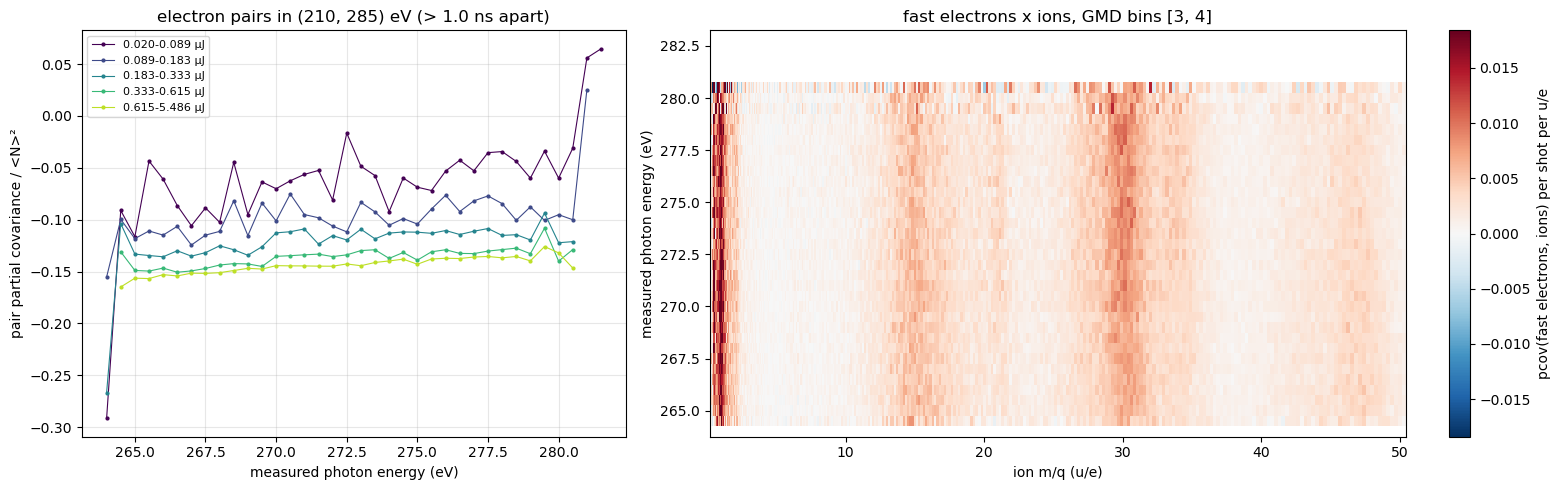

In [22]:
# Partial covariance on GMD within each cell, averaged over the GMD bins COV_GMD_BINS (weighted by shots)
gsel = list(COV_GMD_BINS) if COV_GMD_BINS is not None else [n_g - 2, n_g - 1]
ih = np.flatnonzero(w_hi)
vG = GtG - G ** 2
Dw, DGw = D[..., ih], DtG[..., ih]
cDG = DGw - Dw * G[..., None]
pcov_ee = (DtD[:, :, ih][:, :, :, ih] - Dw[..., :, None] * Dw[..., None, :]
           - cDG[..., :, None] * cDG[..., None, :] / vG[..., None, None])
t_hi = 0.5 * (tof_e_edges[ih] + tof_e_edges[ih + 1])                       # ns
far = np.abs(t_hi[:, None] - t_hi[None, :]) > DEAD_TIME_NS
with np.errstate(invalid="ignore", divide="ignore"):
    pair_rel = np.where(ok, (pcov_ee * far).sum((-1, -2)) / N_hi_rec ** 2, np.nan)   # pairs per shot / <N>^2
cNG = NG_hi - N_hi_rec * G
cCG = CtG - C * G[..., None]
pcov_ei = DtC[:, :, ih, :].sum(2) - N_hi_rec[..., None] * C - cNG[..., None] * cCG / vG[..., None]


def gavg(x):
    # shot-weighted mean over the GMD bins gsel (cells below MIN_SHOTS left out), per photon-energy bin
    wts = np.where(ok[:, gsel], n[:, gsel], 0).astype(float)
    shp = wts.shape + (1,) * (x.ndim - 2)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.nansum(np.nan_to_num(x[:, gsel]) * wts.reshape(shp), axis=1) / wts.sum(1).reshape((-1,) + shp[2:])


mq_e = calibration.mq_of_tof(tof_i_edges)
ei_map = gavg(pcov_ei) / np.diff(mq_e)                                       # per shot per u/e
fig, axs = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})
for g in range(n_g):
    axs[0].plot(E, pair_rel[:, g], ".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
axs[0].set(xlabel="measured photon energy (eV)", ylabel="pair partial covariance / <N>²",
           title=f"electron pairs in {HIGH_KE} eV (> {DEAD_TIME_NS} ns apart)")
axs[0].legend(fontsize=8)
vmax = np.nanpercentile(np.abs(ei_map), 99)
m = axs[1].pcolormesh(mq_e, E_edges, ei_map, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
fig.colorbar(m, ax=axs[1], label="pcov(fast electrons, ions) per shot per u/e")
axs[1].set(xlabel="ion m/q (u/e)", ylabel="measured photon energy (eV)",
           title=f"fast electrons x ions, GMD bins {gsel}")
axs[1].grid(False)
fig.tight_layout()
plt.show()

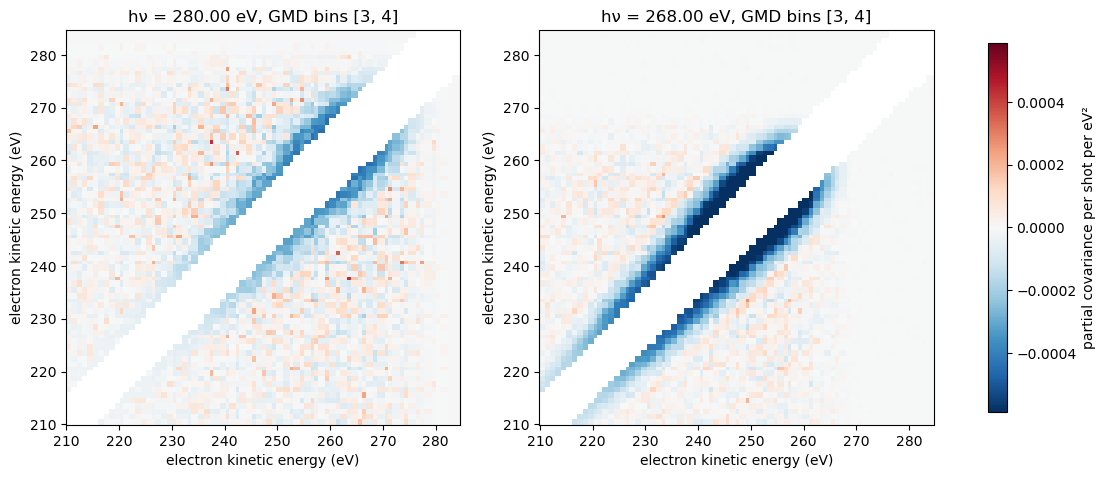

In [23]:
# Electron-electron partial covariance maps (per eV^2) inside HIGH_KE at two photon energies
ee = gavg(pcov_ee)                                                           # (nE, n_hi, n_hi), TOF order
o = np.argsort(kc[ih])
edges_hi = np.sort(calibration.ke_of_tof(tof_e_edges[ih[0]:ih[-1] + 2]))
w_ee = np.diff(edges_hi)
maps = []
for Ec in COMPARE_E:
    e = int(np.argmin(np.abs(E - Ec)))
    mp = ee[e][np.ix_(o, o)] / np.outer(w_ee, w_ee)
    mp[~far[np.ix_(o, o)]] = np.nan
    maps.append((E[e], mp))
vmax = np.nanpercentile(np.abs(np.concatenate([m.ravel() for _, m in maps])), 99)
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, (Ec, mp) in zip(axs, maps):
    mesh = ax.pcolormesh(edges_hi, edges_hi, mp, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set(xlabel="electron kinetic energy (eV)", ylabel="electron kinetic energy (eV)", aspect="equal",
           title=f"hν = {Ec:.2f} eV, GMD bins {gsel}")
    ax.grid(False)
fig.colorbar(mesh, ax=axs, label="partial covariance per shot per eV²", shrink=0.8)
plt.show()